Pada tahap sebelumnya, telah dilakukan pengolahan dan eksperimen awal menggunakan data observasi resmi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Juni 2026 dengan pendekatan prediksi visibility. Namun, seiring dengan perkembangan proses penelitian dan pertimbangan terhadap karakteristik data, pendekatan tersebut kemudian disesuaikan menjadi klasifikasi kondisi visibility. Oleh karena itu, notebook ini melanjutkan proses penelitian dengan berfokus pada penerapan model *machine learning* berbasis pohon keputusan untuk mengklasifikasikan kondisi visibility berdasarkan kategori jarak pandang yang telah ditentukan.

### Data Source & Acquisition

The dataset used in this notebook was collected via web scraping from **[Ogimet](https://www.ogimet.com/synops.phtml.en)**, a public meteorological archive that compiles global surface weather reports transmitted through the **World Meteorological Organization (WMO) Global Telecommunication System (GTS)**. Every hour, surface observations recorded by BMKG at Sultan Thaha Airport are encoded into international **SYNOP (`AAXX`)** messages and broadcast to the GTS network, making Ogimet a direct archive of official station records.

Using a custom Python scraper (`urllib` and `html.parser`), hourly SYNOP tables for **2025** were retrieved from Ogimet's query endpoint (`display_synops2.php`). The raw 5-digit WMO code blocks were decoded into tabular meteorological variables and mapped to match BMKG's standard column naming convention so the raw dataset is ready to be loaded and processed in this notebook.

* **Station:** Sultan Thaha Meteorological Station, Jambi (WMO ID: `96195` | ICAO: `WIJJ`)
* **Period:** January 1 – December 31, 2025 (Hourly resolution in **UTC**)
* **Raw Format:** Decoded Surface Synoptic Reports (`SYNOP / AAXX`) stored as CSV

# 1. Data Loading and Inspection

Tahap ini diawali dengan memuat data observasi resmi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Desember 2025. Data tersebut digunakan sebagai dataset utama dalam penerapan model *machine learning* berbasis pohon keputusan untuk klasifikasi kondisi visibility. Pemeriksaan awal dilakukan untuk memahami struktur dan karakteristik dataset, meliputi jumlah baris dan kolom, tipe data setiap variabel, keberadaan missing value, konsistensi interval waktu pencatatan, serta distribusi dan rentang nilai setiap variabel. Hasil pemeriksaan ini menjadi dasar untuk menentukan langkah pengolahan data pada tahap selanjutnya.

## 1.1 Import Libraries

In [179]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, make_scorer, ConfusionMatrixDisplay, precision_recall_fscore_support, accuracy_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

## 1.2 Load Dataset

Dataset dimuat dari file CSV yang berisi data observasi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Desember 2025. Dataset ini akan digunakan sebagai sumber data utama dalam proses klasifikasi kondisi visibility.

In [115]:
data_df = pd.read_csv('visibility-dataset/stamet_jambi_hour_full_2025.csv')
data_df.head()

,station_name,data_timestamp,wind_dir_deg_dd,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,...,cloud_cover_oktas_m,rainfall_24h_rrrr,rainfall_mm,rainfall_period_h,ix_flag,phenomenon,weather_code_ww,visibility_vv,report_type,raw_synop
0,Stasiun Meteorologi Sultan Thaha,2025-01-01 00:00:00,300,5,1006.8,1009.8,25.8,24.8,25.1,94,...,7,NaN,0.0,NaN,1,Haze/Smoke/Dust,5.0,7.0,SM,AAXX 01004 96195 31457 73005 10258 20248 30068...
1,Stasiun Meteorologi Sultan Thaha,2025-01-01 01:00:00,310,9,1007.6,1010.6,26.7,24.8,25.3,89,...,7,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01014 96195 42460 73109 10267 20248 30076...
2,Stasiun Meteorologi Sultan Thaha,2025-01-01 02:00:00,310,8,1008.0,1011.0,28.0,24.8,25.6,83,...,6,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01024 96195 42460 63108 10280 20248 30080...
3,Stasiun Meteorologi Sultan Thaha,2025-01-01 03:00:00,350,10,1007.9,1010.9,29.5,24.5,25.8,75,...,6,NaN,0.0,NaN,2,Normal,NaN,10.0,SI,AAXX 01034 96195 32460 63510 10295 20245 30079...
4,Stasiun Meteorologi Sultan Thaha,2025-01-01 04:00:00,330,10,1007.3,1010.3,30.6,24.4,26.1,70,...,6,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01044 96195 42460 63310 10306 20244 30073...


## 1.3 Check Data Structure

Pemeriksaan awal dilakukan untuk mengetahui dimensi dataset, meliputi jumlah baris dan kolom, serta tipe data pada masing-masing kolom. Informasi ini digunakan untuk memahami struktur dataset dan mengidentifikasi variabel yang memerlukan penyesuaian tipe data sebelum proses pengolahan lebih lanjut.

In [116]:
data_df.shape

(8244, 21)

In [117]:
data_df.dtypes

station_name                   str
data_timestamp                 str
wind_dir_deg_dd              int64
wind_speed_ff                int64
pressure_qfe_mb_derived    float64
pressure_qff_mb_derived    float64
temp_drybulb_c_tttttt      float64
temp_dewpoint_c_tdtdtd     float64
temp_wetbulb_c             float64
relative_humidity_pc         int64
cloud_low_cover_1          float64
cloud_cover_oktas_m          int64
rainfall_24h_rrrr          float64
rainfall_mm                float64
rainfall_period_h          float64
ix_flag                      int64
phenomenon                     str
weather_code_ww            float64
visibility_vv              float64
report_type                    str
raw_synop                      str
dtype: object

**Notes:**

- Dataset terdiri dari **8.244 baris** dan **21 kolom**.
- Kolom `data_timestamp` masih terbaca sebagai tipe `str` (*string*), sehingga perlu dikonversi ke format `datetime` (`datetime64`) untuk memudahkan pengurutan kronologis dan ekstraksi fitur waktu (jam dan bulan).
- Seluruh parameter meteorologi utama sudah memiliki tipe numerik (`int64` dan `float64`) yang sesuai.

## 1.4 Check Missing Values

Pemeriksaan missing values dilakukan untuk mengetahui jumlah data yang kosong pada setiap variabel. Pemeriksaan ini bertujuan untuk mengevaluasi kelengkapan data serta mengidentifikasi variabel yang memerlukan penanganan pada tahap preprocessing. Perhatian khusus diberikan pada variabel phenomenon karena digunakan sebagai target dalam proses klasifikasi.

In [118]:
data_df.isna().sum()

station_name                  0
data_timestamp                0
wind_dir_deg_dd               0
wind_speed_ff                 0
pressure_qfe_mb_derived       0
pressure_qff_mb_derived       0
temp_drybulb_c_tttttt         0
temp_dewpoint_c_tdtdtd        0
temp_wetbulb_c                0
relative_humidity_pc          0
cloud_low_cover_1             4
cloud_cover_oktas_m           0
rainfall_24h_rrrr          8035
rainfall_mm                5738
rainfall_period_h          7728
ix_flag                       0
phenomenon                    0
weather_code_ww            3773
visibility_vv                 0
report_type                   0
raw_synop                     0
dtype: int64

**Notes:**

- `weather_code_ww` => 3.773

    Variabel `phenomenon` tidak memiliki missing value karena setiap observasi telah diberikan label berdasarkan hasil decoding kode cuaca dan informasi `ix_flag` pada tahap pembentukan dataset.
- `cloud_low_cover_1` => 4
- `rainfall_24h_rrrr` => 8.035
- `rainfall_mm` => 5.738
- `rainfall_period_h` => 7.728

## 1.5 Check Time Range and Interval Consistency

Kolom `data_timestamp` dikonversi ke format datetime agar rentang waktu pengamatan dan selisih waktu antarbaris dapat diperiksa. Pemeriksaan ini bertujuan untuk mengetahui konsistensi interval pencatatan data serta mengidentifikasi kemungkinan adanya lompatan waktu atau duplikasi timestamp.

In [119]:
temp_date = pd.to_datetime(data_df['data_timestamp'], errors='coerce')
temp_date = temp_date.sort_values().reset_index(drop=True)

In [120]:
print(temp_date.min())
print(temp_date.max())

2025-01-01 00:00:00
2025-12-31 23:00:00


In [121]:
interval = temp_date.diff()
print(interval.value_counts())

data_timestamp
0 days 01:00:00    7942
0 days 02:00:00     208
0 days 03:00:00      69
0 days 05:00:00       8
0 days 04:00:00       6
0 days 06:00:00       6
0 days 07:00:00       1
1 days 05:00:00       1
1 days 04:00:00       1
1 days 06:00:00       1
Name: count, dtype: int64


In [122]:
data_df.loc[interval > pd.Timedelta(hours=3), ['data_timestamp', 'report_type']].head(10)

,data_timestamp,report_type
2644,2025-04-23 12:00:00,SM
5054,2025-08-06 02:00:00,SN
5075,2025-08-07 02:00:00,SN
5095,2025-08-08 02:00:00,SN
5116,2025-08-09 02:00:00,SN
5201,2025-08-13 04:00:00,SN
5220,2025-08-14 04:00:00,SN
5239,2025-08-16 03:00:00,SI
5258,2025-08-17 04:00:00,SN
5277,2025-08-18 03:00:00,SI


## 1.6 Check Missing Value Pattern in Cloud Cover Layer 1

Pemeriksaan dilakukan untuk mengetahui pola missing value pada variabel `cloud_low_cover_1` dengan membandingkannya terhadap total tutupan awan (`cloud_cover_oktas_m`). Analisis ini bertujuan mengidentifikasi hubungan antara nilai kosong pada lapisan awan rendah dengan kondisi total tutupan awan, sehingga dapat menentukan penanganan yang sesuai pada tahap preprocessing.

In [123]:
data_df.loc[data_df['cloud_low_cover_1'].isna(), ['cloud_low_cover_1', 'cloud_cover_oktas_m']]

,cloud_low_cover_1,cloud_cover_oktas_m
2813,NaN,9
2814,NaN,9
2815,NaN,9
3681,NaN,7


In [124]:
data_df.loc[(data_df['cloud_low_cover_1'].isna()) & (data_df['cloud_cover_oktas_m'] != 9), ['cloud_low_cover_1', 'cloud_cover_oktas_m', 'raw_synop']]

,cloud_low_cover_1,cloud_cover_oktas_m,raw_synop
3681,NaN,7,AAXX 07004 96195 11936 72701 10248 20243 30082...


In [125]:
print(data_df.loc[3681, 'raw_synop'])

AAXX 07004 96195 11936 72701 10248 20243 30082 40112 53013 60014 71022 86/71 333 20236 50260 55000 56900 59019 86360=


In [126]:
data_df.loc[data_df['cloud_cover_oktas_m'] == 9, ['cloud_low_cover_1', 'cloud_cover_oktas_m']]

,cloud_low_cover_1,cloud_cover_oktas_m
2813,NaN,9
2814,NaN,9
2815,NaN,9


In [127]:
data_df.loc[data_df['cloud_low_cover_1'] == 0, ['cloud_low_cover_1', 'cloud_cover_oktas_m']]

,cloud_low_cover_1,cloud_cover_oktas_m
523,0.0,7
692,0.0,7
714,0.0,7
715,0.0,7
891,0.0,7
...,...,...
7424,0.0,8
7447,0.0,7
7472,0.0,7
7538,0.0,8


**Notes:**

- 3 data dengan `cloud_cover_oktas_m` = 9 juga memiliki nilai kosong pada `cloud_low_cover_1`
- Kode 9 pada `cloud_cover_oktas_m` menunjukkan kondisi langit terhalang sehingga jumlah tutupan awan tidak dapat ditentukan.

## 1.7 Check Value Range (Min/Max)

Pemeriksaan nilai minimum dan maksimum dilakukan untuk mengetahui rentang nilai setiap variabel numerik serta mengidentifikasi kemungkinan nilai ekstrem, anomali, atau nilai yang memerlukan pemeriksaan lebih lanjut berdasarkan karakteristik masing-masing variabel.

Ringkasan nilai minimum dan maksimum seluruh variabel numerik

In [128]:
data_df.describe().T[['min', 'max']]

,min,max
wind_dir_deg_dd,0.00,360.0
wind_speed_ff,0.00,25.0
pressure_qfe_mb_derived,999.20,1012.2
pressure_qff_mb_derived,1002.20,1015.2
temp_drybulb_c_tttttt,21.60,35.2
temp_dewpoint_c_tdtdtd,19.40,26.8
temp_wetbulb_c,20.90,27.8
relative_humidity_pc,42.00,100.0
cloud_low_cover_1,0.00,8.0
cloud_cover_oktas_m,1.00,9.0


## 1.8 Check Unique Value Distribution

Pemeriksaan dilakukan dengan melihat nilai unik pada variabel tertentu beserta frekuensi kemunculannya untuk memahami pola distribusi data dan mengidentifikasi kemungkinan nilai anomali. Pemeriksaan pada variabel visibility juga digunakan untuk mengetahui sebaran nilai jarak pandang sebagai bahan pertimbangan dalam menentukan kategori kelas klasifikasi.

`RAINFALL`

In [129]:
data_df['rainfall_period_h'].sort_values().value_counts()

rainfall_period_h
6.0     307
24.0    209
Name: count, dtype: int64

In [130]:
data_df['rainfall_24h_rrrr'].value_counts().sort_index()

rainfall_24h_rrrr
0.05      31
0.10       4
0.20       6
0.30       5
0.40       5
0.50       1
0.60       3
0.70       3
0.80       1
0.90       3
1.00      12
2.00      16
3.00      12
4.00       6
5.00      16
6.00       5
7.00       8
8.00       5
9.00       5
10.00      3
11.00      2
12.00      2
14.00      3
15.00      3
16.00      2
17.00      3
18.00      2
19.00      1
20.00      2
21.00      3
22.00      1
23.00      1
24.00      2
25.00      2
26.00      1
27.00      2
29.00      3
30.00      1
31.00      2
32.00      1
33.00      2
34.00      1
35.00      1
38.00      1
40.00      1
45.00      1
46.00      1
51.00      2
52.00      1
53.00      2
59.00      1
66.00      1
69.00      2
77.00      1
84.00      1
133.00     1
Name: count, dtype: int64

In [131]:
data_df['rainfall_mm'].value_counts().sort_index()

rainfall_mm
0.00      1990
0.05       100
0.10        18
0.20        19
0.30        13
          ... 
76.00        2
77.00        1
81.00        1
84.00        2
133.00       1
Name: count, Length: 64, dtype: int64

`VISIBILITY`

In [132]:
data_df['visibility_vv'].value_counts().sort_index()

visibility_vv
0.1        1
0.2        9
0.3        6
0.4        4
0.5       10
0.6        4
0.7        7
0.8       10
0.9        4
1.0       33
1.1        5
1.2       14
1.3        7
1.4        3
1.5       46
1.6        7
1.7        7
1.8        9
1.9        7
2.0       96
2.1        3
2.2        6
2.3        8
2.4       12
2.5       68
2.6       11
2.7       10
2.8       12
2.9        9
3.0      234
3.1       10
3.2       11
3.3        8
3.4       14
3.5       56
3.6       11
3.7        8
3.8       10
3.9       11
4.0      276
4.1       12
4.2        7
4.3        8
4.4       10
4.5       33
4.6       10
4.7        8
4.8       13
4.9       11
5.0      926
6.0      549
7.0      901
8.0      574
9.0      305
10.0    3799
12.0       1
Name: count, dtype: int64

In [133]:
data_df.loc[data_df['visibility_vv'] == 0.1, ['data_timestamp']]

,data_timestamp
1117,2025-02-16 22:00:00


In [134]:
print(data_df.loc[1117, 'raw_synop'])

AAXX 16224 96195 41401 60000 10239 20235 30075 40105 74444 82521 333 56000 82614 84460=


In [135]:
data_df['phenomenon'].value_counts().sort_index()

phenomenon
Fog                             49
Haze/Smoke/Dust               2575
Mist                           417
Normal                        3961
Other                           50
Precipitation/Thunderstorm    1192
Name: count, dtype: int64

## 1.9 Check Descriptive Statistics

Menampilkan ringkasan statistik yang meliputi jumlah data, rata-rata, standar deviasi, nilai minimum, maksimum, dan kuartil untuk variabel numerik. Pemeriksaan ini bertujuan untuk memahami karakteristik umum dan distribusi nilai setiap variabel dalam dataset.

In [136]:
data_df.describe()

,wind_dir_deg_dd,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_1,cloud_cover_oktas_m,rainfall_24h_rrrr,rainfall_mm,rainfall_period_h,ix_flag,weather_code_ww,visibility_vv
count,8244.000000,8244.000000,8244.000000,8244.000000,8244.000000,8244.000000,8244.000000,8244.000000,8240.000000,8244.000000,209.000000,2506.000000,516.000000,8244.000000,4471.000000,8244.000000
mean,180.599224,3.601528,1006.396725,1009.412154,27.419432,24.089859,24.997647,83.118753,3.428641,6.961790,11.141388,1.614685,13.290698,1.457666,17.798255,7.657824
std,104.807779,2.304441,1.858386,1.862568,2.729323,0.881279,1.095200,11.913304,1.526560,0.966813,18.062951,7.523811,8.844766,0.498235,23.639907,2.633984
min,0.000000,0.000000,999.200000,1002.200000,21.600000,19.400000,20.900000,42.000000,0.000000,1.000000,0.050000,0.000000,6.000000,1.000000,1.000000,0.100000
25%,110.000000,2.000000,1005.100000,1008.100000,25.200000,23.500000,24.200000,74.000000,2.000000,7.000000,0.600000,0.000000,6.000000,1.000000,5.000000,5.000000
50%,170.000000,3.000000,1006.500000,1009.500000,26.800000,24.150000,25.000000,87.000000,3.000000,7.000000,4.000000,0.000000,6.000000,1.000000,5.000000,8.000000
75%,280.000000,5.000000,1007.700000,1010.700000,29.525000,24.700000,25.800000,94.000000,5.000000,8.000000,14.000000,0.000000,24.000000,2.000000,21.000000,10.000000
max,360.000000,25.000000,1012.200000,1015.200000,35.200000,26.800000,27.800000,100.000000,8.000000,9.000000,133.000000,133.000000,24.000000,2.000000,97.000000,12.000000


## 1.10 Check Duplicate Rows

Pemeriksaan dilakukan untuk mengetahui keberadaan baris data yang terduplikasi, sehingga setiap observasi dalam dataset dapat dipastikan tidak memiliki duplikasi secara keseluruhan.

In [137]:
print(data_df.duplicated().sum())

0


# 2. Exploratory Data Analysis (EDA)

Tahap eksplorasi data dilakukan untuk memahami karakteristik dataset sebelum proses preprocessing. Seluruh analisis pada tahap ini dilakukan pada salinan dataset (`eda_df`) sehingga data asli (`data_df`) tidak mengalami perubahan

## 2.1 Prepare EDA Copy

Salinan dataset dibuat untuk keperluan eksplorasi, kemudian ditambahkan beberapa kolom bantu berupa waktu dalam WIB, jam, bulan, dan selisih suhu dengan titik embun (dew point depression). Kolom bantu ini hanya digunakan untuk analisis dan belum menjadi bagian dari proses feature engineering. Daftar variabel numerik juga disiapkan pada tahap ini. Variabel arah angin tidak dimasukkan karena merupakan data sudut (0–360°), sehingga tidak sesuai dianalisis seperti variabel numerik biasa.

In [154]:
eda_df = data_df.copy()

In [155]:
eda_df['data_timestamp'] = pd.to_datetime(eda_df['data_timestamp'])
eda_df['datetime_wib'] = eda_df['data_timestamp'] + pd.Timedelta(hours=7)

In [156]:
eda_df['hour_wib'] = eda_df['datetime_wib'].dt.hour
eda_df['month_wib'] = eda_df['datetime_wib'].dt.month

In [157]:
eda_df['dewpoint_depression'] = eda_df['temp_drybulb_c_tttttt'] - eda_df['temp_dewpoint_c_tdtdtd']

In [158]:
num_cols = ['wind_speed_ff', 'pressure_qfe_mb_derived', 'pressure_qff_mb_derived',
            'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c',
            'relative_humidity_pc', 'cloud_low_cover_1', 'cloud_cover_oktas_m',
            'rainfall_24h_rrrr', 'rainfall_mm', 'visibility_vv', 'dewpoint_depression']

## 2.2 Target Distribution

Pemeriksaan distribusi variabel target `phenomenon` dilakukan untuk mengetahui jumlah dan proporsi data pada setiap kelas fenomena. Informasi ini digunakan untuk mengidentifikasi adanya ketidakseimbangan kelas yang perlu diperhatikan pada tahap pemodelan dan evaluasi.

In [159]:
eda_df['phenomenon'].value_counts()

phenomenon
Normal                        3961
Haze/Smoke/Dust               2575
Precipitation/Thunderstorm    1192
Mist                           417
Other                           50
Fog                             49
Name: count, dtype: int64

In [161]:
eda_df['phenomenon'].value_counts(normalize=True).round(2)

phenomenon
Normal                        0.48
Haze/Smoke/Dust               0.31
Precipitation/Thunderstorm    0.14
Mist                          0.05
Other                         0.01
Fog                           0.01
Name: proportion, dtype: float64

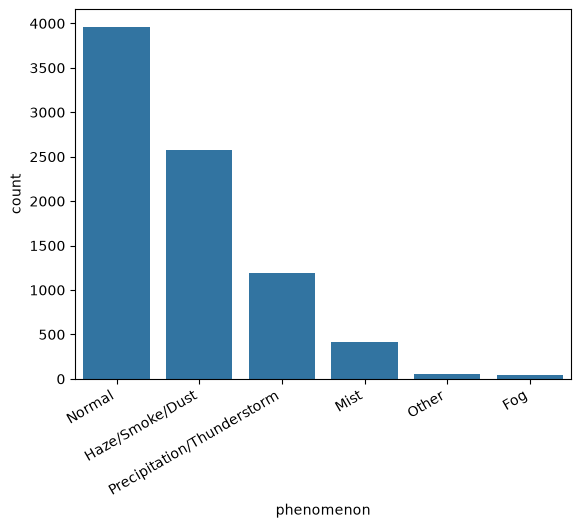

In [194]:
sns.countplot(data=eda_df, x='phenomenon', order=eda_df['phenomenon'].value_counts().index)
plt.xticks(rotation=30, ha='right')
plt.show()

**Notes:**

Dari hasil distribusi target, terlihat bahwa jumlah data pada setiap kelas `phenomenon` tidak merata. Kelas *Normal* memiliki jumlah data paling banyak, yaitu 3.961 data (48%), sedangkan kelas *Fog* dan *Other* memiliki jumlah data paling sedikit, masing-masing 49 dan 50 data (sekitar 1%).

Perbedaan jumlah data ini perlu diperhatikan pada tahap pemodelan karena model bisa lebih mudah mengenali kelas yang memiliki banyak data dibandingkan kelas yang jumlah datanya sedikit. Oleh karena itu, perlu dipertimbangkan cara untuk menangani ketidakseimbangan kelas serta penggunaan metrik evaluasi yang dapat menunjukkan hasil prediksi pada masing-masing kelas.

## 2.3 Numeric Feature Distribution

Distribusi setiap variabel numerik ditampilkan dalam bentuk histogram untuk mengetahui bentuk sebaran data, seperti kecenderungan miring (skewed), penumpukan pada nilai tertentu, serta keberadaan nilai yang tampak ekstrem. Pemeriksaan ini membantu menentukan perlunya penanganan lebih lanjut pada tahap preprocessing.

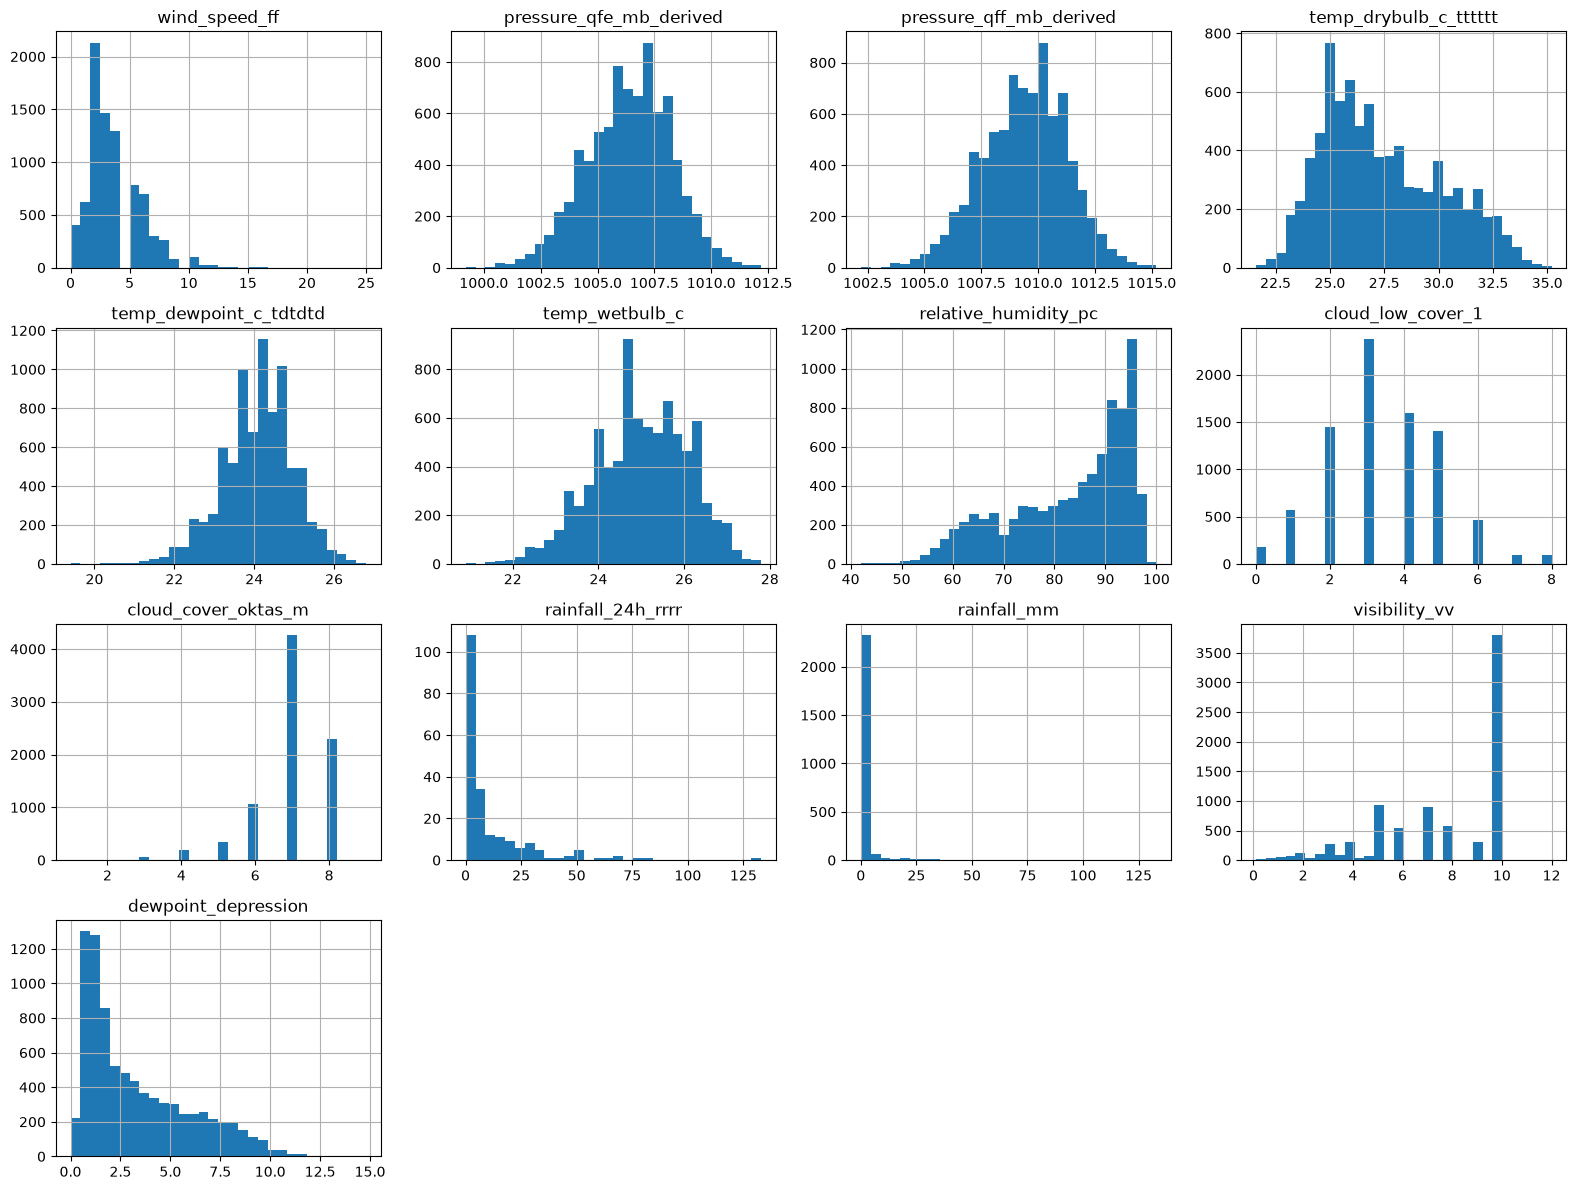

In [171]:
eda_df[num_cols].hist(bins=30, figsize=(16,12))
plt.tight_layout()
plt.show()

In [187]:
def hist_text(s, bins=10):
    s = s.dropna()
    counts, edges = np.histogram(s, bins=bins)
    return ' | '.join(f'{edges[i]:.1f}-{edges[i+1]:.1f}: {counts[i]}' for i in range(len(counts)))

print(eda_df[num_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T.round(2).to_string())

for col in num_cols:
    print(f'\n{col}\n  {hist_text(eda_df[col])}')

# kolom diskrit: lebih jelas pakai value counts
for col in ['cloud_low_cover_1', 'cloud_cover_oktas_m']:
    print(f'\n{col}:', eda_df[col].value_counts().sort_index().to_dict())

# rainfall: proporsi nol dan NaN
print('\nrainfall_mm  nol  :', round((eda_df['rainfall_mm'] == 0).mean() * 100, 1), '%')
print('rainfall_mm  NaN :', round(eda_df['rainfall_mm'].isna().mean() * 100, 1), '%')

                          count     mean   median    std      min     max  skew
wind_speed_ff            8244.0     3.60     3.00   2.30     0.00    25.0  1.22
pressure_qfe_mb_derived  8244.0  1006.40  1006.50   1.86   999.20  1012.2 -0.18
pressure_qff_mb_derived  8244.0  1009.41  1009.50   1.86  1002.20  1015.2 -0.19
temp_drybulb_c_tttttt    8244.0    27.42    26.80   2.73    21.60    35.2  0.48
temp_dewpoint_c_tdtdtd   8244.0    24.09    24.15   0.88    19.40    26.8 -0.33
temp_wetbulb_c           8244.0    25.00    25.00   1.10    20.90    27.8 -0.26
relative_humidity_pc     8244.0    83.12    87.00  11.91    42.00   100.0 -0.72
cloud_low_cover_1        8240.0     3.43     3.00   1.53     0.00     8.0  0.25
cloud_cover_oktas_m      8244.0     6.96     7.00   0.97     1.00     9.0 -1.48
rainfall_24h_rrrr         209.0    11.14     4.00  18.06     0.05   133.0  2.98
rainfall_mm              2506.0     1.61     0.00   7.52     0.00   133.0  7.91
visibility_vv            8244.0     7.66

**Notes:**

- Kecepatan angin lebih banyak terkumpul pada nilai rendah dan semakin sedikit pada nilai yang lebih tinggi
- Tekanan udara memiliki sebaran yang relatif terpusat pada rentang nilai tertentu
- Suhu udara, suhu titik embun, dan suhu bola basah, data cenderung terkumpul pada rentang nilai tertentu
- Kelembapan relatif menunjukkan penumpukan data pada nilai yang cukup tinggi
- Tutupan awan memiliki pola sebaran yang lebih terkonsentrasi pada beberapa nilai tertentu
- Sebagian besar data curah hujan berada pada nilai rendah, hanya sedikit data yang memiliki nilai tinggi. Akan tetapi, nilai kosong yang ditemukan sekitar 69,6% dari keseluruhan data
- Visibility menunjukkan penumpukan data yang cukup besar pada nilai 10 km
- Dewpoint depression lebih banyak memiliki nilai pada rentang rendah dan semakin sedikit pada rentang yang lebih tinggi

Secara umum, histogram menunjukkan bahwa beberapa variabel memiliki sebaran yang tidak merata dan penumpukan data pada nilai tertentu. Pola tersebut perlu diperhatikan dalam pemeriksaan data dan tahap preprocessing selanjutnya.

## 2.4 Numeric Features by Phenomenon

Perbandingan nilai setiap variabel numerik pada masing-masing kelas fenomena dilakukan menggunakan boxplot untuk melihat apakah terdapat perbedaan karakteristik antar fenomena. Uji Kruskal-Wallis digunakan untuk mengukur apakah perbedaan tersebut signifikan secara statistik. Uji ini dipilih karena tidak mengasumsikan data berdistribusi normal dan dapat digunakan pada kelas dengan jumlah data yang berbeda-beda. Analisis ini juga mencakup `visibility_vv` sebagai salah satu fitur model.

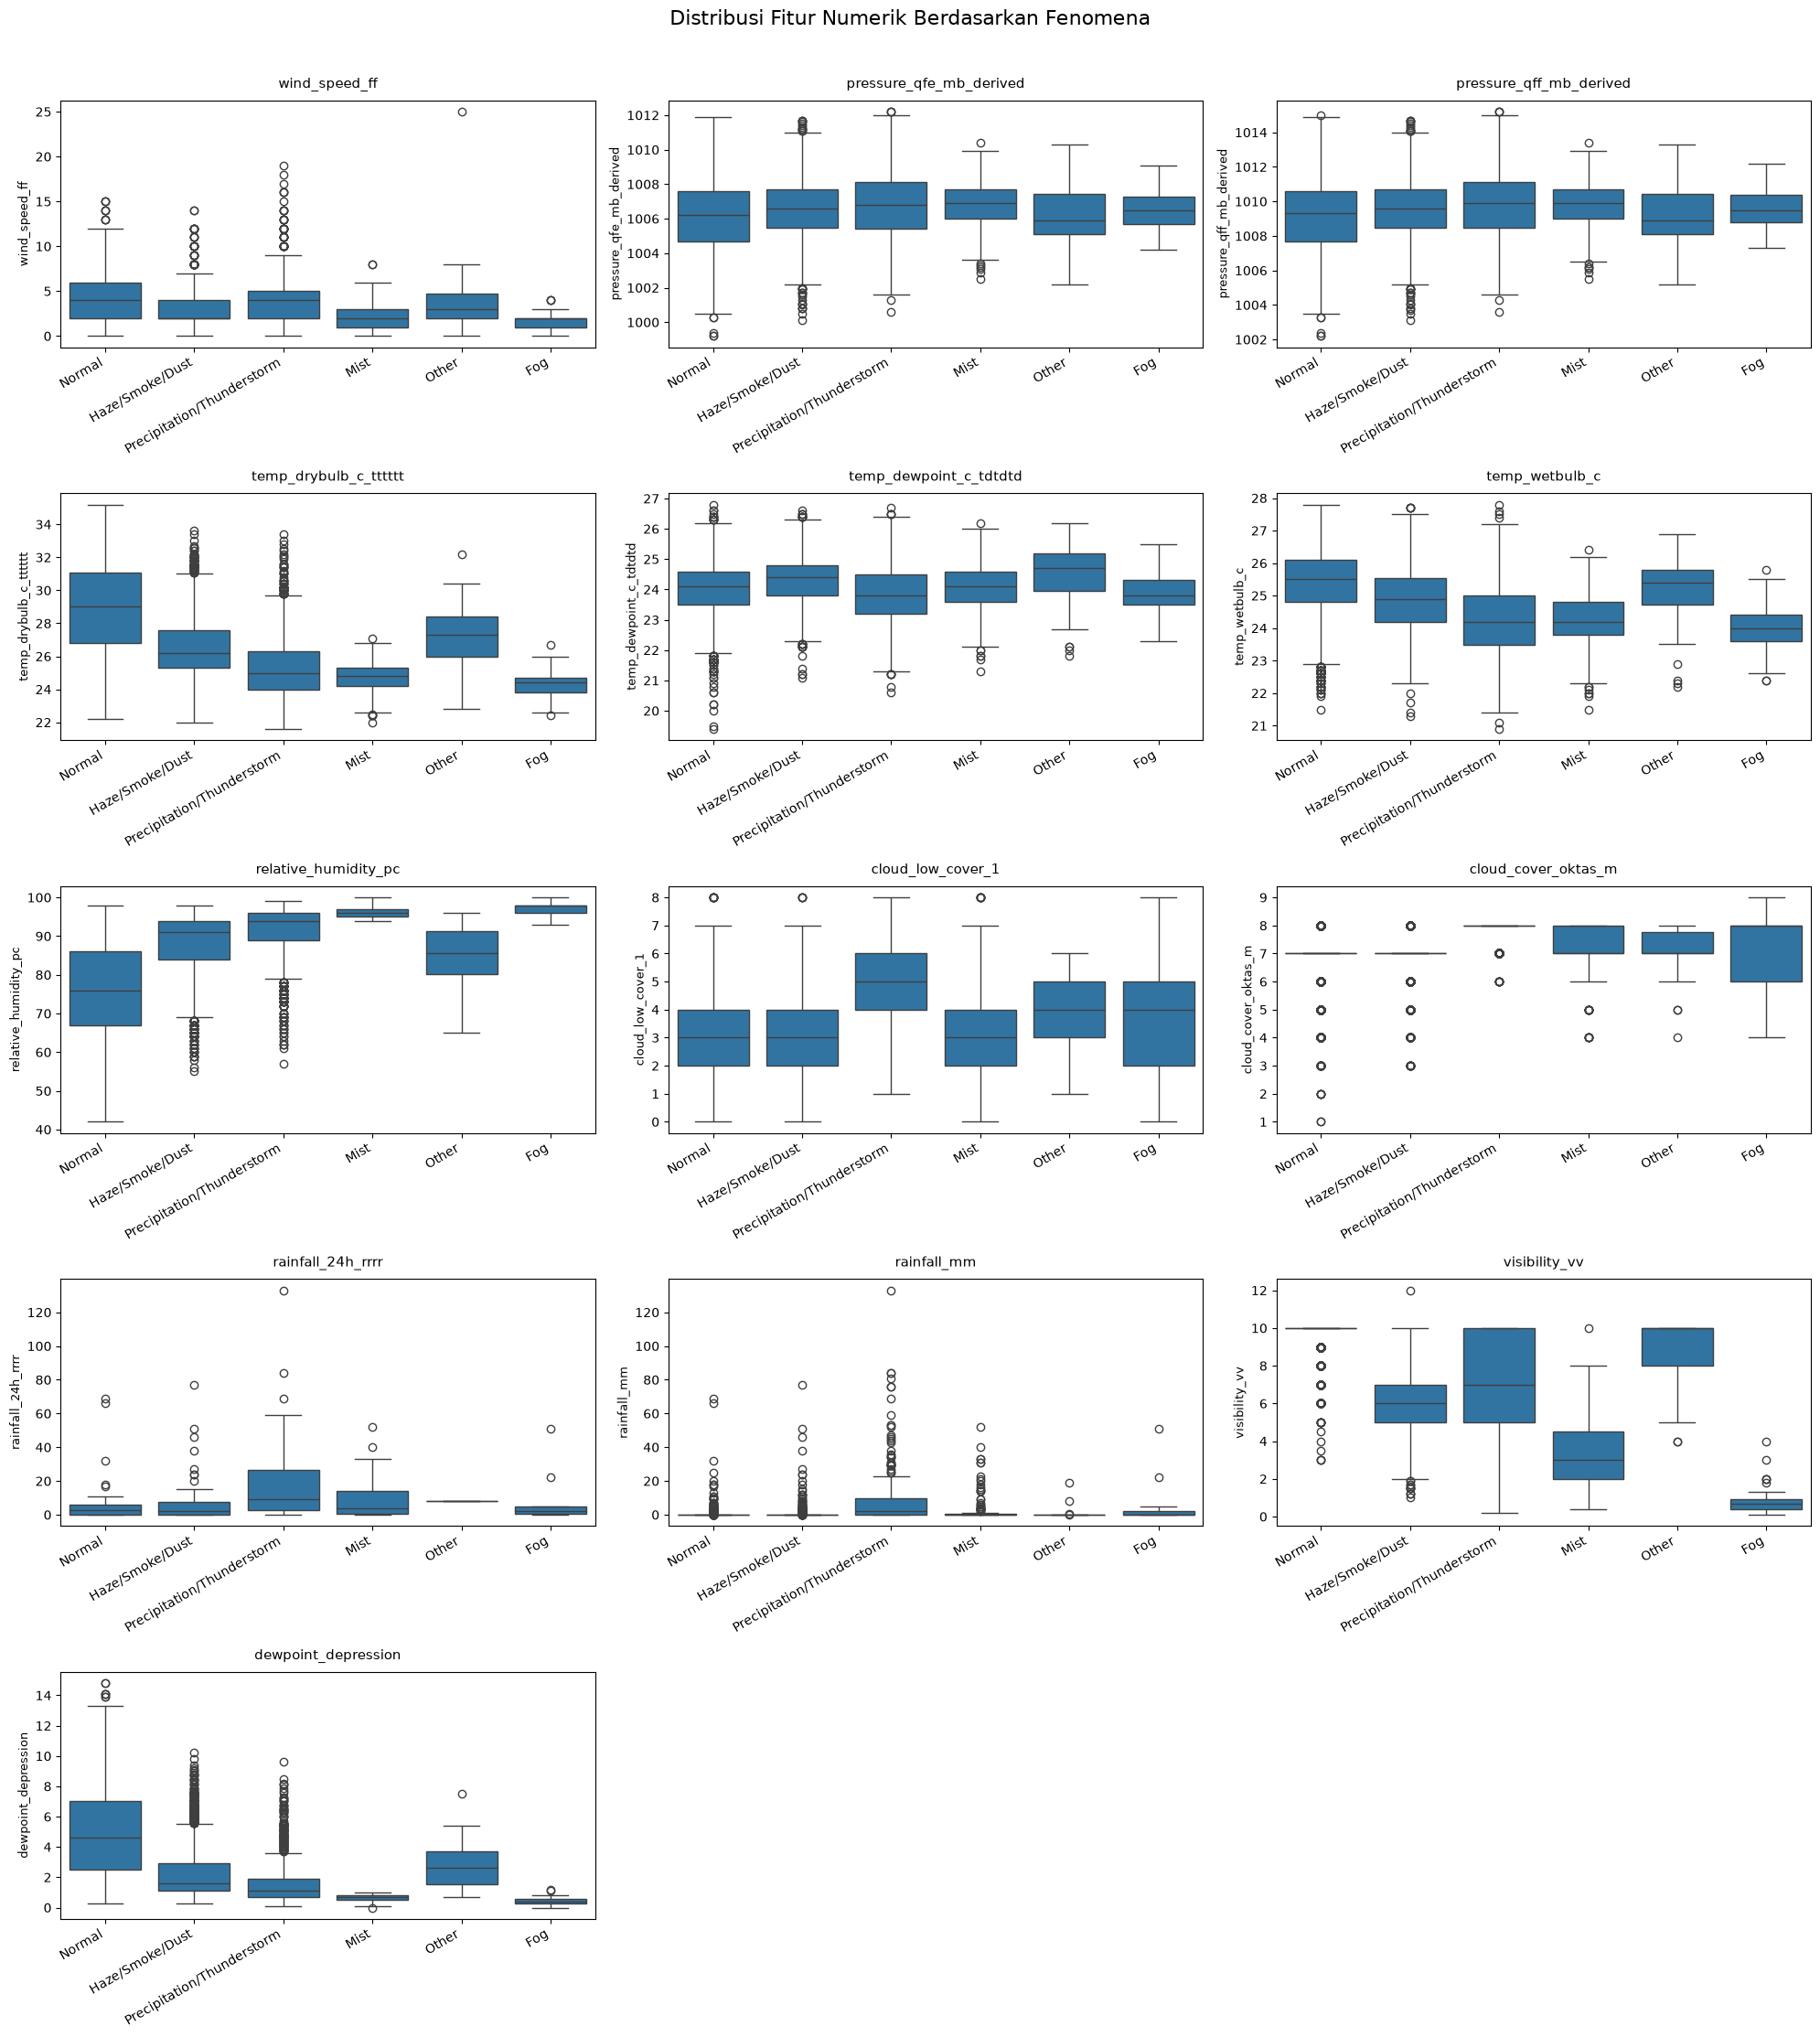

In [206]:
fig, axes = plt.subplots(5, 3, figsize=(20, 22))

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(
        data=eda_df,
        x='phenomenon',
        y=col,
        order=eda_df['phenomenon'].value_counts().index,
        ax=ax
    )

    ax.set_title(col, fontsize=11, pad=10)
    ax.set_xlabel('')
    ax.set_ylabel(col, fontsize=9)
    
    ax.tick_params(axis='x', labelrotation=30)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

# Menghilangkan subplot yang tidak digunakan
for ax in axes.flatten()[len(num_cols):]:
    ax.remove()

plt.suptitle(
    'Distribusi Fitur Numerik Berdasarkan Fenomena',
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [207]:
results = []

for col in num_cols:
    groups = [
        group[col].dropna().values
        for _, group in eda_df.groupby('phenomenon')
    ]

    stat, p = kruskal(*groups)

    results.append({
        'Feature': col,
        'H-Statistic': stat,
        'P-Value': p,
        'Significant': p < 0.05
    })

kruskal_results = pd.DataFrame(results)

display(
    kruskal_results.style.format({
        'H-Statistic': '{:.2f}',
        'P-Value': '{:.3e}'
    })
)

,Feature,H-Statistic,P-Value,Significant
0,wind_speed_ff,1113.89,1.314e-238,True
1,pressure_qfe_mb_derived,145.21,1.399e-29,True
2,pressure_qff_mb_derived,148.97,2.208e-30,True
3,temp_drybulb_c_tttttt,2575.86,0.000e+00,True
4,temp_dewpoint_c_tdtdtd,297.71,3.106e-62,True
5,temp_wetbulb_c,1311.75,1.815e-281,True
6,relative_humidity_pc,3283.87,0.000e+00,True
7,cloud_low_cover_1,1265.89,1.566e-271,True
8,cloud_cover_oktas_m,1490.18,0.000e+00,True
9,rainfall_24h_rrrr,20.99,8.119e-04,True


In [200]:
for col in num_cols:
    t = eda_df.groupby('phenomenon')[col].agg(
        n='count', min='min',
        q1=lambda x: x.quantile(.25), median='median',
        q3=lambda x: x.quantile(.75), max='max'
    ).round(2)
    print(f'\n{col}')
    print(t.to_string())


wind_speed_ff
                               n  min   q1  median    q3  max
phenomenon                                                   
Fog                           49    0  1.0     2.0  2.00    4
Haze/Smoke/Dust             2575    0  2.0     2.0  4.00   14
Mist                         417    0  1.0     2.0  3.00    8
Normal                      3961    0  2.0     4.0  6.00   15
Other                         50    0  2.0     3.0  4.75   25
Precipitation/Thunderstorm  1192    0  2.0     4.0  5.00   19

pressure_qfe_mb_derived
                               n     min      q1  median       q3     max
phenomenon                                                               
Fog                           49  1004.2  1005.7  1006.5  1007.30  1009.1
Haze/Smoke/Dust             2575  1000.1  1005.5  1006.6  1007.70  1011.7
Mist                         417  1002.5  1006.0  1006.9  1007.70  1010.4
Normal                      3961   999.2  1004.7  1006.2  1007.60  1011.9
Other               

**Notes:**

- **Visibility, kelembapan relatif, dan *dewpoint depression*:** Kelas `Fog` dan `Mist` cenderung memiliki nilai visibility dan *dewpoint depression* yang lebih rendah, serta kelembapan relatif yang lebih tinggi dibandingkan beberapa kelas lainnya.
- **Suhu udara dan suhu bola basah:** Kelas `Normal` memiliki nilai median yang lebih tinggi dibandingkan kelas `Fog` dan `Mist`.
- **Tutupan awan dan curah hujan:** Kelas `Precipitation/Thunderstorm` cenderung memiliki nilai yang lebih tinggi dibandingkan sebagian besar kelas lainnya.
- **Tekanan udara dan suhu titik embun:** Memiliki nilai median yang relatif berdekatan antarkelas.

Uji ***Kruskal-Wallis*** dilakukan untuk mengetahui apakah terdapat perbedaan distribusi yang signifikan secara statistik pada setiap variabel numerik berdasarkan kelas fenomena. Hasil pengujian menunjukkan bahwa seluruh variabel memiliki nilai *p-value* di bawah 0,05. Hal ini menunjukkan bahwa terdapat perbedaan distribusi yang signifikan secara statistik pada setidaknya satu kelas fenomena. Nilai H-statistik menunjukkan besarnya statistik perbedaan peringkat antarkelompok dalam pengujian. Variabel visibility memiliki nilai H-statistik tertinggi, yaitu 5650,61, sedangkan curah hujan 24 jam memiliki nilai terendah, yaitu 20,99. Namun, nilai H-statistik tidak secara langsung menunjukkan tingkat kepentingan suatu fitur dalam model klasifikasi.

Hasil analisis ini menunjukkan bahwa fitur-fitur numerik memiliki pola distribusi yang berbeda berdasarkan fenomena yang diamati. Namun, uji *Kruskal-Wallis* belum menunjukkan pasangan kelas mana saja yang memiliki perbedaan signifikan. Secara keseluruhan, hasil analisis ini memberikan gambaran awal mengenai karakteristik setiap fitur yang dapat dipertimbangkan dalam proses pemodelan.

## 2.5 Correlation Between Numeric Feature

Korelasi antar variabel numerik dihitung menggunakan metode Spearman untuk mengetahui kekuatan hubungan antar fitur. Metode ini dipilih karena tidak mengasumsikan hubungan linear dan lebih tahan terhadap nilai ekstrem. Analisis ini bertujuan mengidentifikasi fitur yang saling berkorelasi tinggi (multikolinearitas) sebagai bahan pertimbangan pemilihan fitur. Korelasi hanya dihitung untuk variabel numerik.

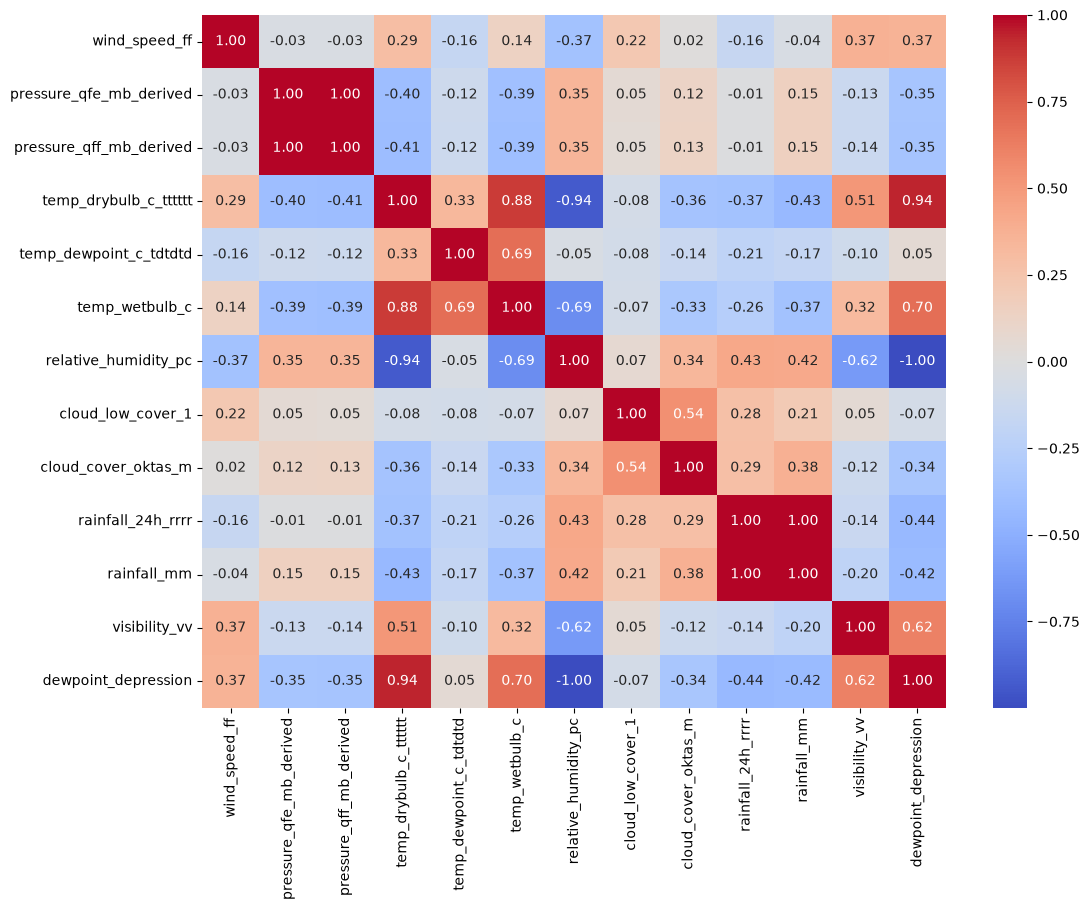

In [181]:
plt.figure(figsize=(12, 9))
sns.heatmap(eda_df[num_cols].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='coolwarm', center=0)
plt.show()

In [190]:
print(eda_df[num_cols].corr(method='spearman').round(2).to_string())

                         wind_speed_ff  pressure_qfe_mb_derived  pressure_qff_mb_derived  temp_drybulb_c_tttttt  temp_dewpoint_c_tdtdtd  temp_wetbulb_c  relative_humidity_pc  cloud_low_cover_1  cloud_cover_oktas_m  rainfall_24h_rrrr  rainfall_mm  visibility_vv  dewpoint_depression
wind_speed_ff                     1.00                    -0.03                    -0.03                   0.29                   -0.16            0.14                 -0.37               0.22                 0.02              -0.16        -0.04           0.37                 0.37
pressure_qfe_mb_derived          -0.03                     1.00                     1.00                  -0.40                   -0.12           -0.39                  0.35               0.05                 0.12              -0.01         0.15          -0.13                -0.35
pressure_qff_mb_derived          -0.03                     1.00                     1.00                  -0.41                   -0.12           -0.39   

**Notes:**

- Tekanan QFE dan QFF memiliki korelasi positif sangat kuat (1,00), yang menunjukkan bahwa kedua variabel memiliki hubungan yang hampir sempurna.
- Suhu udara memiliki korelasi positif sangat kuat dengan *dewpoint depression* (0,94) dan suhu bola basah (0,88).
- Kelembapan relatif memiliki korelasi negatif sangat kuat dengan suhu udara (-0,94) dan *dewpoint depression* (-1,00).
- Curah hujan 24 jam dan curah hujan memiliki korelasi positif sangat kuat (1,00). Namun, korelasi ini hanya dihitung berdasarkan 209 baris data yang memiliki nilai pada kedua variabel, sehingga tidak mewakili keseluruhan observasi.
- Visibility memiliki korelasi negatif kuat dengan kelembapan relatif (-0,62) dan korelasi positif kuat dengan *dewpoint depression* (0,62).
- Tutupan awan rendah dan tutupan awan total memiliki korelasi positif sedang (0,54).

Berdasarkan hasil korelasi Spearman, terdapat beberapa pasangan variabel numerik yang memiliki hubungan sangat kuat. Hubungan tersebut terutama terlihat pada variabel tekanan udara, suhu udara, kelembapan relatif, *dewpoint depression*, serta curah hujan. Hasil ini menunjukkan bahwa beberapa fitur memiliki hubungan yang erat dan berpotensi membawa informasi yang serupa. Oleh karena itu, korelasi antarfitur perlu diperhatikan dalam proses pemilihan fitur dan pemodelan. Namun, korelasi yang tinggi tidak secara langsung menunjukkan bahwa salah satu fitur harus dihapus, sehingga keputusan pemilihan fitur perlu mempertimbangkan karakteristik data dan hasil evaluasi model.

## 2.6 Temporal Pattern

Pola temporal fenomena dianalisis berdasarkan jam pengamatan (WIB) dan bulan untuk mengetahui apakah jenis fenomena tertentu cenderung muncul pada waktu tertentu. Proporsi fenomena dihitung per jam dan per bulan agar tidak dipengaruhi perbedaan jumlah observasi pada setiap waktu.

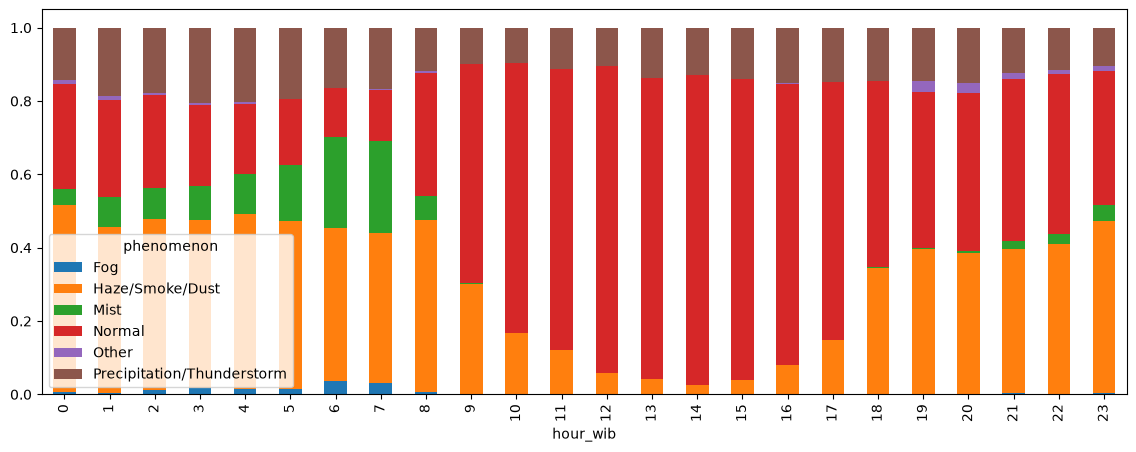

In [182]:
ct_hour = pd.crosstab(eda_df['hour_wib'], eda_df['phenomenon'], normalize='index')
ct_hour.plot(kind='bar', stacked=True, figsize=(14, 5))
plt.show()

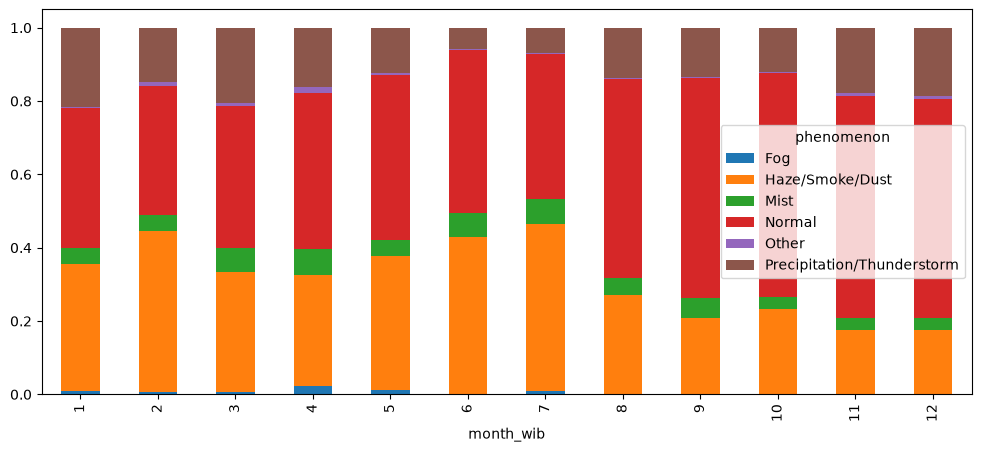

In [184]:
ct_month = pd.crosstab(eda_df['month_wib'], eda_df['phenomenon'], normalize='index')
ct_month.plot(kind='bar', stacked=True, figsize=(12, 5))
plt.show()

In [191]:
ct_hour_n = pd.crosstab(eda_df['hour_wib'], eda_df['phenomenon'])
print((ct_hour_n.div(ct_hour_n.sum(axis=1), axis=0) * 100).round(1).to_string())

ct_month_n = pd.crosstab(eda_df['month_wib'], eda_df['phenomenon'])
print((ct_month_n.div(ct_month_n.sum(axis=1), axis=0) * 100).round(1).to_string())

print(ct_hour_n.sum(axis=1).to_string())    # jumlah observasi per jam
print(ct_month_n.sum(axis=1).to_string())   # jumlah observasi per bulan

phenomenon  Fog  Haze/Smoke/Dust  Mist  Normal  Other  Precipitation/Thunderstorm
hour_wib                                                                         
0           0.6             51.1   4.3    28.7    0.9                        14.4
1           0.3             45.5   8.1    26.4    1.1                        18.5
2           1.1             46.6   8.6    25.4    0.6                        17.7
3           1.7             45.8   9.2    22.1    0.6                        20.6
4           1.4             47.9  10.7    19.2    0.6                        20.3
5           1.4             46.0  15.2    17.8    0.0                        19.5
6           3.7             41.8  24.7    13.4    0.0                        16.5
7           3.1             40.9  25.2    13.8    0.3                        16.6
8           0.6             46.9   6.4    33.8    0.3                        11.9
9           0.0             30.1   0.3    59.6    0.0                         9.9
10          0.0 

**Notes:**

**Berdasarkan jam pengamatan:**

- **Fog dan Mist:** Cenderung lebih banyak ditemukan pada dini hari hingga pagi.
- **Haze/Smoke/Dust:** Memiliki proporsi tinggi pada malam hingga pagi, kemudian cenderung menurun pada siang hari.
- **Normal:** Lebih dominan pada siang hari, terutama sekitar pukul 10.00–16.00.
- **Precipitation/Thunderstorm:** Cenderung memiliki proporsi lebih tinggi pada dini hari hingga pagi dibandingkan beberapa jam siang hari.
- **Other:** Memiliki proporsi relatif kecil dan hanya muncul pada beberapa jam pengamatan.

**Berdasarkan bulan pengamatan:**

- **Haze/Smoke/Dust:** Cenderung memiliki proporsi lebih tinggi pada awal hingga pertengahan tahun, terutama sekitar Februari, Juni, dan Juli.
- **Normal:** Cenderung lebih dominan pada Agustus hingga Desember.
- **Mist:** Memiliki proporsi yang relatif lebih tinggi pada April dibandingkan bulan lainnya.
- **Precipitation/Thunderstorm:** Cenderung memiliki proporsi lebih tinggi pada Januari dan Maret, kemudian menurun pada Juni dan Juli.
- **Fog dan Other:** Memiliki proporsi relatif kecil sepanjang periode pengamatan.

Berdasarkan analisis pola temporal, terlihat bahwa proporsi setiap fenomena mengalami perubahan berdasarkan jam dan bulan pengamatan. Pada pola per jam, kelas Fog dan Mist cenderung memiliki proporsi lebih tinggi pada dini hari hingga pagi, sedangkan kelas Normal lebih dominan pada siang hari, terutama pada pukul 10.00–16.00. Kelas Haze/Smoke/Dust juga menunjukkan perubahan proporsi, dengan nilai yang cenderung lebih tinggi pada malam hingga pagi dan menurun pada siang hari.

Sementara itu, berdasarkan bulan pengamatan, kelas Haze/Smoke/Dust memiliki proporsi tertinggi pada Juli, sedangkan kelas Normal lebih dominan pada Agustus hingga Desember. Kelas Precipitation/Thunderstorm memiliki proporsi yang relatif tinggi pada Januari dan Maret, kemudian menurun pada Juni dan Juli. Adapun kelas Fog dan Other memiliki proporsi yang relatif kecil sepanjang periode pengamatan.

Secara keseluruhan, hasil analisis menunjukkan bahwa distribusi fenomena memiliki pola yang berbeda berdasarkan waktu pengamatan. Informasi ini dapat menjadi gambaran awal mengenai karakteristik temporal setiap fenomena dan bahan pertimbangan dalam proses pemodelan. Pola bulanan yang terlihat hanya berdasarkan satu tahun pengamatan, sehingga belum cukup untuk menyimpulkan adanya pola musiman. Selain itu, jumlah observasi pada Agustus lebih sedikit dibandingkan sebagian besar bulan lainnya.

## 2.7 Label Origin Check

Pemeriksaan dilakukan untuk melihat hubungan antara phenomenon dengan `ix_flag` dan `weather_code_ww`, karena label fenomena dibentuk berdasarkan hasil decoding kedua kolom tersebut. Hasil pemeriksaan ini menjadi dasar pertimbangan untuk tidak menggunakan keduanya sebagai fitur model guna menghindari kebocoran informasi (data leakage).

In [185]:
print(pd.crosstab(eda_df['phenomenon'], eda_df['ix_flag']))

ix_flag                        1     2
phenomenon                            
Fog                           49     0
Haze/Smoke/Dust             2575     0
Mist                         417     0
Normal                       188  3773
Other                         50     0
Precipitation/Thunderstorm  1192     0


In [186]:
print(pd.crosstab(eda_df['phenomenon'], eda_df['weather_code_ww'].isna()))

weather_code_ww             False  True 
phenomenon                              
Fog                            49      0
Haze/Smoke/Dust              2575      0
Mist                          417      0
Normal                        188   3773
Other                          50      0
Precipitation/Thunderstorm   1192      0


**Notes:**

- **`ix_flag`:** Memiliki hubungan yang jelas dengan label `phenomenon`. Seluruh kelas selain `Normal` menggunakan nilai `ix_flag = 1`, sedangkan kelas `Normal` sebagian besar menggunakan nilai `ix_flag = 2`.
- **`weather_code_ww`:** Seluruh data pada kelas selain `Normal` memiliki kode cuaca, sedangkan sebagian besar data `Normal` tidak memiliki kode tersebut.
- Kedua variabel memiliki hubungan langsung dengan proses pembentukan label `phenomenon`, sehingga tidak digunakan sebagai fitur prediktor untuk menghindari *data leakage*.

# 3. Preprocessing

Tahap ini melakukan pembersihan dan transformasi data berdasarkan seluruh temuan dari tahap Inspection dan EDA sebelumnya, agar data siap digunakan untuk pemodelan. Seluruh proses dilakukan pada salinan data (`clean_df`), sehingga data_df asli tetap terjaga sebagai referensi mentah.

## 3.1 Create Working Copy

Salinan dataset dibuat untuk diproses sehingga data mentah (`data_df`) tetap tersimpan sebagai referensi.

In [208]:
clean_df = data_df.copy()
clean_df.head()

,station_name,data_timestamp,wind_dir_deg_dd,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,...,cloud_cover_oktas_m,rainfall_24h_rrrr,rainfall_mm,rainfall_period_h,ix_flag,phenomenon,weather_code_ww,visibility_vv,report_type,raw_synop
0,Stasiun Meteorologi Sultan Thaha,2025-01-01 00:00:00,300,5,1006.8,1009.8,25.8,24.8,25.1,94,...,7,NaN,0.0,NaN,1,Haze/Smoke/Dust,5.0,7.0,SM,AAXX 01004 96195 31457 73005 10258 20248 30068...
1,Stasiun Meteorologi Sultan Thaha,2025-01-01 01:00:00,310,9,1007.6,1010.6,26.7,24.8,25.3,89,...,7,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01014 96195 42460 73109 10267 20248 30076...
2,Stasiun Meteorologi Sultan Thaha,2025-01-01 02:00:00,310,8,1008.0,1011.0,28.0,24.8,25.6,83,...,6,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01024 96195 42460 63108 10280 20248 30080...
3,Stasiun Meteorologi Sultan Thaha,2025-01-01 03:00:00,350,10,1007.9,1010.9,29.5,24.5,25.8,75,...,6,NaN,0.0,NaN,2,Normal,NaN,10.0,SI,AAXX 01034 96195 32460 63510 10295 20245 30079...
4,Stasiun Meteorologi Sultan Thaha,2025-01-01 04:00:00,330,10,1007.3,1010.3,30.6,24.4,26.1,70,...,6,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01044 96195 42460 63310 10306 20244 30073...


## 3.2 Fix Data Structure

Kolom `data_timestamp` dikonversi ke tipe datetime sesuai temuan pada tahap Inspection.

In [209]:
clean_df['data_timestamp'] = pd.to_datetime(clean_df['data_timestamp'], errors='coerce')
print(clean_df['data_timestamp'].dtypes)

datetime64[us]


## 3.3 Drop Unused Columns

Kolom yang tidak digunakan sebagai fitur dihapus:
- `weather_code_ww` dan `ix_flag` dihapus karena menjadi dasar pembentukan label phenomenon
- `pressure_qfe_mb_derived` dihapus karena berkorelasi 1,00 dengan `pressure_qff_mb_derived`
- `rainfall_24h_rrrr` dan `rainfall_period_h` dihapus karena lebih dari 97% dan 93% nilainya kosong
- `station_name`, `report_type`, dan `raw_synop` merupakan informasi identitas dan data mentah yang tidak relevan sebagai fitur

In [210]:
clean_df.columns

Index(['station_name', 'data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff',
       'pressure_qfe_mb_derived', 'pressure_qff_mb_derived',
       'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c',
       'relative_humidity_pc', 'cloud_low_cover_1', 'cloud_cover_oktas_m',
       'rainfall_24h_rrrr', 'rainfall_mm', 'rainfall_period_h', 'ix_flag',
       'phenomenon', 'weather_code_ww', 'visibility_vv', 'report_type',
       'raw_synop'],
      dtype='str')

In [211]:
drop_cols = ['station_name', 'weather_code_ww', 'ix_flag', 'pressure_qfe_mb_derived',
             'rainfall_24h_rrrr', 'rainfall_period_h', 'report_type', 'raw_synop']

clean_df.drop(columns=drop_cols, inplace=True)
clean_df.columns

Index(['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff',
       'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt',
       'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c', 'relative_humidity_pc',
       'cloud_low_cover_1', 'cloud_cover_oktas_m', 'rainfall_mm', 'phenomenon',
       'visibility_vv'],
      dtype='str')

## 3.4 Check Outlier Candidates

Dua nilai yang tampak tidak biasa pada tahap Inspection dan EDA diperiksa kembali pada data sumber, yaitu kecepatan angin 25 dan visibility 12,0, untuk menentukan apakah nilai tersebut valid

In [212]:
print(clean_df.loc[clean_df['wind_speed_ff'] == 25, ['data_timestamp', 'phenomenon']])
print(data_df.loc[clean_df['wind_speed_ff'] == 25, 'raw_synop'].values)

print(clean_df.loc[clean_df['visibility_vv'] == 12, ['data_timestamp', 'phenomenon']])
print(data_df.loc[clean_df['visibility_vv'] == 12, 'raw_synop'].values)

          data_timestamp phenomenon
3368 2025-05-24 13:00:00      Other
<StringArray>
['AAXX 24134 96195 41460 72725 10287 20233 30056 40086 71322 81922 333 56000 57905 81912 84613 85460 80970=']
Length: 1, dtype: str
     data_timestamp       phenomenon
6074     2025-09-25  Haze/Smoke/Dust
<StringArray>
['AAXX 25004 96195 31462 61502 10244 20233 30076 40105 53011 70522 83571 333 20240 50420 55105 56000 58003 83613 84460=']
Length: 1, dtype: str


**Notes:**

- Kecepatan angin sebesar 25 diperiksa berdasarkan kode SYNOP mentah 72725. Hasil decoding menunjukkan nilai tersebut sesuai dengan kode kecepatan angin `ff=25`. Berdasarkan indikator satuan `iw=4`, nilai tersebut dinyatakan dalam knot, sehingga bukan merupakan kesalahan pembacaan data.
- Visibility sebesar 12,0 diperiksa berdasarkan kode SYNOP mentah 31462. Kode visibility `VV=62` menunjukkan jarak pandang sebesar 12 km, sehingga nilai tersebut juga sesuai dengan data pengamatan sumber.
- Berdasarkan hasil pemeriksaan, kedua nilai tersebut dinyatakan valid dan tetap dipertahankan dalam dataset karena tidak menunjukkan kesalahan pencatatan atau decoding.

## 3.5 Handle Missing Values

Menangani nilai hilang pada variabel yang teridentifikasi memiliki missing value. Hanya dua kolom yang masih punya missing value setelah penghapusan, yaitu `cloud_low_cover_1` (4 baris) dan `rainfall_mm` (5.738 baris)

`cloud_low_cover_1`

In [213]:
clean_df.loc[clean_df['cloud_low_cover_1'].isna(), ['phenomenon', 'cloud_cover_oktas_m', 'visibility_vv']]

,phenomenon,cloud_cover_oktas_m,visibility_vv
2813,Fog,9,0.2
2814,Fog,9,0.2
2815,Fog,9,0.2
3681,Mist,7,3.6


In [215]:
idx_nan = clean_df[clean_df['cloud_low_cover_1'].isna()].index
idx_before = idx_nan - 1
idx_after = idx_nan + 1
idx_all = idx_nan.union(idx_before).union(idx_after).sort_values()

clean_df.loc[idx_all, ['data_timestamp', 'cloud_low_cover_1', 'phenomenon', 'cloud_cover_oktas_m', 'visibility_vv']]

,data_timestamp,cloud_low_cover_1,phenomenon,cloud_cover_oktas_m,visibility_vv
2812,2025-04-30 19:00:00,4.0,Fog,8,1.0
2813,2025-04-30 20:00:00,NaN,Fog,9,0.2
2814,2025-04-30 21:00:00,NaN,Fog,9,0.2
2815,2025-04-30 22:00:00,NaN,Fog,9,0.2
2816,2025-04-30 23:00:00,2.0,Fog,6,0.2
3680,2025-06-06 22:00:00,1.0,Normal,7,9.0
3681,2025-06-07 00:00:00,NaN,Mist,7,3.6
3682,2025-06-07 01:00:00,1.0,Haze/Smoke/Dust,4,7.0


In [216]:
clean_df['cloud_low_cover_1'] = clean_df['cloud_low_cover_1'].ffill()
print(clean_df['cloud_low_cover_1'].isna().sum())

0


`rainfall_mm`

In [219]:
print(((data_df['rainfall_mm'] > 0) == data_df['rainfall_period_h'].notna()).mean())

hr = clean_df['data_timestamp'].dt.hour
print(pd.crosstab(hr, data_df['rainfall_period_h']))
print(data_df.loc[data_df['rainfall_mm'] == 0, 'rainfall_period_h'].notna().sum())

1.0
rainfall_period_h  6.0   24.0
data_timestamp               
0                     0   209
6                    92     0
12                  114     0
18                  101     0
0


In [220]:
clean_df = clean_df.drop(columns=['rainfall_mm'])

In [221]:
clean_df.head()

,data_timestamp,wind_dir_deg_dd,wind_speed_ff,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_1,cloud_cover_oktas_m,phenomenon,visibility_vv
0,2025-01-01 00:00:00,300,5,1009.8,25.8,24.8,25.1,94,3.0,7,Haze/Smoke/Dust,7.0
1,2025-01-01 01:00:00,310,9,1010.6,26.7,24.8,25.3,89,4.0,7,Normal,10.0
2,2025-01-01 02:00:00,310,8,1011.0,28.0,24.8,25.6,83,3.0,6,Normal,10.0
3,2025-01-01 03:00:00,350,10,1010.9,29.5,24.5,25.8,75,4.0,6,Normal,10.0
4,2025-01-01 04:00:00,330,10,1010.3,30.6,24.4,26.1,70,4.0,6,Normal,10.0


## 3.5 Finalize Data Types

Mengonversi kembali kolom yang sempat bertipe float akibat adanya missing value menjadi integer, setelah seluruh nilai hilang berhasil ditangani pada tahap sebelumnya.

In [225]:
print((clean_df['cloud_low_cover_1'] % 1 == 0).all())
print((clean_df['cloud_cover_oktas_m'] % 1 == 0).all())

True
True


In [226]:
clean_df['cloud_low_cover_1'] = clean_df['cloud_low_cover_1'].astype('int8')
clean_df['cloud_cover_oktas_m'] = clean_df['cloud_cover_oktas_m'].astype('int8')

In [227]:
clean_df[['cloud_low_cover_1', 'cloud_cover_oktas_m']].dtypes

cloud_low_cover_1      int8
cloud_cover_oktas_m    int8
dtype: object

In [228]:
clean_df[['cloud_low_cover_1', 'cloud_cover_oktas_m']].head(5)

,cloud_low_cover_1,cloud_cover_oktas_m
0,3,7
1,4,7
2,3,6
3,4,6
4,4,6


## 3.6 Convert Timestamp to Local Time (WIB)

Mengonversi `data_timestamp` dari UTC ke WIB (UTC+7), agar analisis dan fitur berbasis waktu selanjutnya konsisten dengan pola diurnal visibility yang telah diidentifikasi pada tahap EDA.

In [229]:
date_position = clean_df.columns.get_loc('data_timestamp') + 1
clean_df.insert(date_position, 'datetime_wib', clean_df['data_timestamp'] + pd.Timedelta(hours=7))

In [230]:
clean_df[['data_timestamp', 'datetime_wib']].head(5)

,data_timestamp,datetime_wib
0,2025-01-01 00:00:00,2025-01-01 07:00:00
1,2025-01-01 01:00:00,2025-01-01 08:00:00
2,2025-01-01 02:00:00,2025-01-01 09:00:00
3,2025-01-01 03:00:00,2025-01-01 10:00:00
4,2025-01-01 04:00:00,2025-01-01 11:00:00


In [231]:
print('first date: ', clean_df['datetime_wib'].min())
print('last date: ', clean_df['datetime_wib'].max())

first date:  2025-01-01 07:00:00
last date:  2026-01-01 06:00:00


In [233]:
clean_df.columns

Index(['data_timestamp', 'datetime_wib', 'wind_dir_deg_dd', 'wind_speed_ff',
       'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt',
       'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c', 'relative_humidity_pc',
       'cloud_low_cover_1', 'cloud_cover_oktas_m', 'phenomenon',
       'visibility_vv'],
      dtype='str')

In [232]:
clean_df.head(5)

,data_timestamp,datetime_wib,wind_dir_deg_dd,wind_speed_ff,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_1,cloud_cover_oktas_m,phenomenon,visibility_vv
0,2025-01-01 00:00:00,2025-01-01 07:00:00,300,5,1009.8,25.8,24.8,25.1,94,3,7,Haze/Smoke/Dust,7.0
1,2025-01-01 01:00:00,2025-01-01 08:00:00,310,9,1010.6,26.7,24.8,25.3,89,4,7,Normal,10.0
2,2025-01-01 02:00:00,2025-01-01 09:00:00,310,8,1011.0,28.0,24.8,25.6,83,3,6,Normal,10.0
3,2025-01-01 03:00:00,2025-01-01 10:00:00,350,10,1010.9,29.5,24.5,25.8,75,4,6,Normal,10.0
4,2025-01-01 04:00:00,2025-01-01 11:00:00,330,10,1010.3,30.6,24.4,26.1,70,4,6,Normal,10.0


# 4. Feature Engineering

Tahap feature engineering dilakukan dengan membentuk variabel baru dari data yang telah dibersihkan. Pembentukan fitur ini didasarkan pada karakteristik data dan pola yang ditemukan pada tahap EDA, dengan tujuan membantu model mengenali pola yang berkaitan dengan masing-masing fenomena meteorologi.

## 4.1 Dewpoint Depression

Menghitung selisih antara suhu udara dan titik embun `(temp_drybulb_c_tttttt - temp_dewpoint_c_tdtdtd)`, untuk merangkum informasi suhu dan kelembapan secara lebih ringkas

**Dew point depression**, yaitu <u>*selisih antara suhu udara dan titik embun*</u>, merupakan indikator penting dalam mengidentifikasi potensi pembentukan kabut. Semakin kecil nilai selisih ini, semakin dekat kondisi udara terhadap titik saturasi, yang meningkatkan kemungkinan terbentuknya kabut atau penurunan visibility.

**Dew point** (titik embun) itu suhu di mana udara harus didinginkan sampai jadi **jenuh/saturated** (kelembapan relatif = 100%), sampai uap air mulai mengembun jadi titik-titik air (contoh: embun di rumput pagi hari, atau kabut).

Jadi **dew point depression** itu ngukur **seberapa "jauh" suhu udara saat ini dari titik jenuhnya**:
- **Depression kecil** (temp dan dew point deket) → udara hampir jenuh, kelembapan tinggi, kondisi mendekati pembentukan kabut/embun
- **Depression besar** (temp dan dew point jauh) → udara masih jauh dari jenuh, kelembapan relatif rendah, kecil kemungkinan kabut

```
Temp = 25°C, Dew Point = 24°C  →  Depression = 1°C   (udara SANGAT lembap, dekat titik jenuh)
Temp = 30°C, Dew Point = 15°C  →  Depression = 15°C  (udara kering, jauh dari jenuh)
```

In [234]:
dew_dep_position = clean_df.columns.get_loc('temp_dewpoint_c_tdtdtd') + 1
clean_df.insert(dew_dep_position, 'dewpoint_depression', clean_df['temp_drybulb_c_tttttt'] - clean_df['temp_dewpoint_c_tdtdtd'])

In [235]:
clean_df[['temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'dewpoint_depression']].head(5)

,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,dewpoint_depression
0,25.8,24.8,1.0
1,26.7,24.8,1.9
2,28.0,24.8,3.2
3,29.5,24.5,5.0
4,30.6,24.4,6.2


In [236]:
clean_df['dewpoint_depression'].describe()

count    8244.000000
mean        3.329573
std         2.652626
min         0.000000
25%         1.100000
50%         2.400000
75%         5.100000
max        14.800000
Name: dewpoint_depression, dtype: float64

## 4.2 Cyclical Time Encoding

Mengonversi jam dan bulan menjadi representasi sin dan cos, agar model dapat menangkap sifat siklis waktu (misalnya jam 23:00 dekat dengan jam 00:00).

**Ekstraksi Fitur Waktu Dasar**

In [242]:
position = clean_df.columns.get_loc('datetime_wib') + 1
clean_df.insert(position, 'hour', clean_df['datetime_wib'].dt.hour)

**Cyclic Encoding for Hour (Periode 24 Jam)**

In [244]:
position = clean_df.columns.get_loc('hour') + 1
clean_df.insert(position, 'hour_sin', np.sin(2 * np.pi * clean_df['hour'] / 24))
position = clean_df.columns.get_loc('hour') + 2
clean_df.insert(position, 'hour_cos', np.cos(2 * np.pi * clean_df['hour'] / 24))

In [251]:
time = clean_df[['datetime_wib', 'hour', 'hour_sin', 'hour_cos']]

In [252]:
time.isna().sum()

datetime_wib    0
hour            0
hour_sin        0
hour_cos        0
dtype: int64

In [253]:
time.head(5)

,datetime_wib,hour,hour_sin,hour_cos
0,2025-01-01 07:00:00,7,0.965926,-0.258819
1,2025-01-01 08:00:00,8,0.866025,-0.500000
2,2025-01-01 09:00:00,9,0.707107,-0.707107
3,2025-01-01 10:00:00,10,0.500000,-0.866025
4,2025-01-01 11:00:00,11,0.258819,-0.965926


## 4.3 Wind Direction Encoding (Sin/Cos)

Mengonversi `wind_dir_deg_dd` menjadi representasi sin dan cos, karena arah angin bersifat sirkular (0° dan 360° merepresentasikan arah yang sama) sehingga tidak bisa diperlakukan sebagai nilai linear biasa.

In [237]:
position = clean_df.columns.get_loc('wind_dir_deg_dd') + 1
clean_df.insert(position, 'wind_dir_sin', np.sin(np.deg2rad(clean_df['wind_dir_deg_dd'])))

In [238]:
position = clean_df.columns.get_loc('wind_dir_deg_dd') + 2
clean_df.insert(position, 'wind_dir_cos', np.cos(np.deg2rad(clean_df['wind_dir_deg_dd'])))

In [239]:
wind_direction = clean_df[['wind_dir_deg_dd', 'wind_dir_sin', 'wind_dir_cos']]

In [240]:
wind_direction.isna().sum()

wind_dir_deg_dd    0
wind_dir_sin       0
wind_dir_cos       0
dtype: int64

In [241]:
wind_direction.head(5)

,wind_dir_deg_dd,wind_dir_sin,wind_dir_cos
0,300,-0.866025,0.500000
1,310,-0.766044,0.642788
2,310,-0.766044,0.642788
3,350,-0.173648,0.984808
4,330,-0.500000,0.866025


In [250]:
clean_df.loc[clean_df['wind_speed_ff'] == 0, 'wind_dir_deg_dd'].value_counts(dropna=False)

wind_dir_deg_dd
0    401
Name: count, dtype: int64

## 4.4 Calm Wind Flag

Fitur `is_calm` dibuat untuk menandai kondisi angin tenang (calm wind) berdasarkan kecepatan angin. Fitur ini menggunakan nilai biner, yaitu 1 untuk menunjukkan kondisi angin tenang ketika kecepatan angin bernilai 0, dan 0 untuk menunjukkan kondisi selain angin tenang. Penambahan fitur ini bertujuan memberikan informasi eksplisit kepada model mengenai kondisi angin tenang.

In [254]:
position = clean_df.columns.get_loc('wind_speed_ff') + 1
clean_df.insert(position, 'is_calm', (clean_df['wind_speed_ff'] == 0).astype(int))

In [255]:
clean_df['is_calm'].value_counts()

is_calm
0    7843
1     401
Name: count, dtype: int64

## 4.5 Feature Engineering Validation

Tahap ini dilakukan untuk memeriksa hasil pembentukan fitur baru guna memastikan bahwa perhitungan telah dilakukan dengan benar, nilai yang dihasilkan berada dalam rentang yang sesuai, serta tidak terdapat missing value yang muncul akibat proses feature engineering.

In [263]:
engineered_features = ['dewpoint_depression', 'wind_dir_sin', 'wind_dir_cos', 'hour_sin', 'hour_cos', 'is_calm']
clean_df[engineered_features].isna().sum()

dewpoint_depression    0
wind_dir_sin           0
wind_dir_cos           0
hour_sin               0
hour_cos               0
is_calm                0
dtype: int64

In [264]:
clean_df[engineered_features].describe()

,dewpoint_depression,wind_dir_sin,wind_dir_cos,hour_sin,hour_cos,is_calm
count,8244.000000,8.244000e+03,8244.000000,8244.000000,8.244000e+03,8244.000000
mean,3.329573,2.854564e-02,-0.037699,-0.008090,6.140842e-03,0.048641
std,2.652626,6.508650e-01,0.757799,0.705034,7.091867e-01,0.215130
min,0.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000e+00,0.000000
25%,1.100000,-6.427876e-01,-0.766044,-0.707107,-7.071068e-01,0.000000
50%,2.400000,1.224647e-16,-0.173648,0.000000,6.123234e-17,0.000000
75%,5.100000,6.427876e-01,0.766044,0.707107,7.071068e-01,0.000000
max,14.800000,1.000000e+00,1.000000,1.000000,1.000000e+00,1.000000


In [265]:
clean_df.head(10)

,data_timestamp,datetime_wib,hour,hour_sin,hour_cos,month,month_sin,month_cos,wind_dir_deg_dd,wind_dir_sin,...,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,dewpoint_depression,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_1,cloud_cover_oktas_m,phenomenon,visibility_vv
0,2025-01-01 00:00:00,2025-01-01 07:00:00,7,9.659258e-01,-0.258819,1,0.5,0.866025,300,-0.866025,...,1009.8,25.8,24.8,1.0,25.1,94,3,7,Haze/Smoke/Dust,7.0
1,2025-01-01 01:00:00,2025-01-01 08:00:00,8,8.660254e-01,-0.500000,1,0.5,0.866025,310,-0.766044,...,1010.6,26.7,24.8,1.9,25.3,89,4,7,Normal,10.0
2,2025-01-01 02:00:00,2025-01-01 09:00:00,9,7.071068e-01,-0.707107,1,0.5,0.866025,310,-0.766044,...,1011.0,28.0,24.8,3.2,25.6,83,3,6,Normal,10.0
3,2025-01-01 03:00:00,2025-01-01 10:00:00,10,5.000000e-01,-0.866025,1,0.5,0.866025,350,-0.173648,...,1010.9,29.5,24.5,5.0,25.8,75,4,6,Normal,10.0
4,2025-01-01 04:00:00,2025-01-01 11:00:00,11,2.588190e-01,-0.965926,1,0.5,0.866025,330,-0.500000,...,1010.3,30.6,24.4,6.2,26.1,70,4,6,Normal,10.0
5,2025-01-01 05:00:00,2025-01-01 12:00:00,12,1.224647e-16,-1.000000,1,0.5,0.866025,10,0.173648,...,1009.9,29.8,24.5,5.3,25.9,73,5,7,Normal,10.0
6,2025-01-01 06:00:00,2025-01-01 13:00:00,13,-2.588190e-01,-0.965926,1,0.5,0.866025,320,-0.642788,...,1008.9,29.5,24.2,5.3,25.6,73,4,7,Normal,10.0
7,2025-01-01 07:00:00,2025-01-01 14:00:00,14,-5.000000e-01,-0.866025,1,0.5,0.866025,330,-0.500000,...,1007.8,30.0,24.6,5.4,26.0,73,3,7,Normal,10.0
8,2025-01-01 08:00:00,2025-01-01 15:00:00,15,-7.071068e-01,-0.707107,1,0.5,0.866025,310,-0.766044,...,1007.0,30.2,24.8,5.4,26.2,73,4,7,Haze/Smoke/Dust,8.0
9,2025-01-01 09:00:00,2025-01-01 16:00:00,16,-8.660254e-01,-0.500000,1,0.5,0.866025,80,0.984808,...,1007.0,29.8,25.0,4.8,26.3,75,4,7,Normal,10.0


**Notes:**

- Seluruh fitur baru berhasil dibentuk tanpa menghasilkan missing value
- Nilai setiap fitur juga berada dalam rentang yang sesuai dengan perhitungan dan karakteristiknya
- Fitur `dewpoint_depression` memiliki nilai antara 0 hingga 14,8°C
- Fitur hasil encoding sin dan cos berada pada rentang -1 hingga 1
- Fitur `is_calm` memiliki nilai biner 0 dan 1 untuk membedakan kondisi angin tenang dan bukan angin tenang

# 5. Label Definition

Tahap ini menetapkan variabel target yang akan diprediksi oleh model, yaitu `phenomenon`. Berbeda dengan pendekatan sebelumnya yang membentuk kelas dari ambang batas visibility, variabel target pada tahap ini sudah berupa kategori hasil pengamatan, sehingga tidak diperlukan penentuan ambang batas baru. Tahap ini berfokus pada peninjauan distribusi kelas dan pengubahan label ke bentuk numerik agar dapat diproses oleh algoritma.

## 5.1 Target Class Review

Meninjau jumlah dan proporsi setiap kelas pada `phenomenon`. Peninjauan ini diperlukan untuk mengetahui tingkat ketidakseimbangan kelas serta mengidentifikasi kelas dengan jumlah data yang sangat sedikit, karena kelas semacam ini dapat sulit dipelajari oleh model dan berisiko tidak terwakili pada data uji setelah pembagian data berbasis waktu.

In [267]:
clean_df['phenomenon'].value_counts()

phenomenon
Normal                        3961
Haze/Smoke/Dust               2575
Precipitation/Thunderstorm    1192
Mist                           417
Other                           50
Fog                             49
Name: count, dtype: int64

**Notes:**

Distribusi kelas target menunjukkan ketidakseimbangan jumlah data. Kelas `Normal` memiliki jumlah observasi terbanyak, yaitu 3.961 data, sedangkan kelas `Fog` dan `Other` memiliki jumlah observasi paling sedikit, masing-masing 49 dan 50 data. Kondisi ini perlu diperhatikan pada tahap pemodelan dan evaluasi karena model berpotensi lebih sulit mengenali kelas dengan jumlah data yang sedikit.

## 5.2 Encode Target Label

Mengubah label kategori pada `phenomenon` menjadi bilangan bulat menggunakan pemetaan (label_map) yang didefinisikan secara eksplisit. Pemetaan dibuat secara manual agar urutan kode setiap kelas terdokumentasi dengan jelas dan dapat digunakan kembali, misalnya saat menampilkan hasil prediksi dalam bentuk nama fenomena. Proses ini hanya berupa pemetaan tetap yang tidak mempelajari pola dari data, sehingga aman dilakukan sebelum pembagian data.

In [271]:
label_map = {
    'Fog': 0,
    'Haze/Smoke/Dust': 1,
    'Mist': 2,
    'Normal': 3,
    'Other': 4,
    'Precipitation/Thunderstorm': 5
}

clean_df['phenomenon_encoded'] = clean_df['phenomenon'].map(label_map).astype('int8')

In [272]:
print(clean_df['phenomenon_encoded'].isna().sum())

0


In [273]:
clean_df['phenomenon_encoded'].value_counts().sort_index()

phenomenon_encoded
0      49
1    2575
2     417
3    3961
4      50
5    1192
Name: count, dtype: int64

# 6. Data Splitting

Tahap ini membagi dataset menjadi data latih (training set) dan data uji (testing set) menggunakan metode Stratified Group Split berdasarkan tanggal pengamatan. Pembagian dilakukan dengan mempertimbangkan distribusi kelas pada variabel target phenomenon_encoded serta mengelompokkan data berdasarkan tanggal. Metode ini bertujuan agar distribusi kelas pada data latih dan data uji relatif seimbang serta seluruh observasi pada tanggal yang sama tetap berada dalam kelompok yang sama.

In [274]:
pd.crosstab(clean_df['datetime_wib'].dt.month, clean_df['phenomenon'])

phenomenon,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Precipitation/Thunderstorm
datetime_wib,,,,,,
1,6,257,32,283,2,159
2,5,291,30,234,7,99
3,5,236,48,278,7,148
4,16,208,50,293,11,112
5,8,266,31,325,5,89
6,1,299,46,313,1,41
7,6,323,49,282,2,48
8,0,153,26,306,1,78
9,0,146,38,417,2,94


## 6.1 Create Date Group

Membuat kolom date dengan mengambil informasi tanggal dari `datetime_wib`. Kolom ini digunakan sebagai identitas kelompok (group) dalam proses pembagian dataset, sehingga observasi yang berasal dari tanggal yang sama tidak terpisah ke dalam data latih dan data uji.

In [275]:
clean_df['date'] = clean_df['datetime_wib'].dt.date

## 6.2 Stratified Group Split

Membagi dataset menjadi lima kelompok (fold) menggunakan metode `StratifiedGroupKFold`. Proses pembagian mempertimbangkan distribusi kelas target `phenomenon_encoded` dan menggunakan kolom `date` sebagai kelompok pengamatan. Empat kelompok digunakan sebagai data latih, sedangkan satu kelompok digunakan sebagai data uji, dengan proporsi pembagian sekitar 80:20

In [276]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(clean_df, clean_df['phenomenon_encoded'], groups=clean_df['date']))

train_df = clean_df.iloc[train_idx]
test_df = clean_df.iloc[test_idx]

## 6.3 Split Distribution Check

Memeriksa distribusi jumlah dan proporsi setiap kelas pada data latih dan data uji untuk mengetahui keseimbangan kelas setelah proses pembagian. Pemeriksaan ini juga memastikan bahwa seluruh observasi pada tanggal yang sama hanya berada pada salah satu bagian dataset.

In [285]:
train_counts = train_df['phenomenon'].value_counts()
test_counts = test_df['phenomenon'].value_counts()

train_percentages = train_df['phenomenon'].value_counts(normalize=True) * 100
test_percentages = test_df['phenomenon'].value_counts(normalize=True) * 100

In [286]:
split_distribution = pd.DataFrame({
    'Train Count': train_counts,
    'Train (%)': train_percentages,
    'Test Count': test_counts,
    'Test (%)': test_percentages
}).fillna(0).round(2)

display(split_distribution)

,Train Count,Train (%),Test Count,Test (%)
phenomenon,,,,
Fog,38,0.58,11,0.67
Haze/Smoke/Dust,2062,31.26,513,31.15
Mist,335,5.08,82,4.98
Normal,3169,48.04,792,48.09
Other,39,0.59,11,0.67
Precipitation/Thunderstorm,954,14.46,238,14.45


In [287]:
overlapping_dates = set(train_df['date']) & set(test_df['date'])

In [288]:
print("Jumlah tanggal yang sama pada train dan test:", len(overlapping_dates))
print("Tidak ada tanggal yang tumpang tindih:", len(overlapping_dates) == 0)

Jumlah tanggal yang sama pada train dan test: 0
Tidak ada tanggal yang tumpang tindih: True


In [289]:
total_data = len(clean_df)
train_size = len(train_df)
test_size = len(test_df)

In [290]:
print(f"Total data : {total_data}")
print(f"Train      : {train_size} ({train_size / total_data * 100:.2f}%)")
print(f"Test       : {test_size} ({test_size / total_data * 100:.2f}%)")

Total data : 8244
Train      : 6597 (80.02%)
Test       : 1647 (19.98%)


**Notes:**

Berdasarkan hasil pemeriksaan, proses pembagian dataset menghasilkan 6.597 data latih (80,02%) dan 1.647 data uji (19,98%), sehingga proporsinya mendekati 80:20. Distribusi kelas pada data latih dan data uji juga relatif seimbang, dengan persentase setiap kelas yang tidak jauh berbeda. Kelas minoritas Fog dan Other masing-masing memiliki 11 data pada data uji, sehingga keduanya tetap terwakili dalam proses evaluasi. Selain itu, hasil pemeriksaan menunjukkan tidak terdapat tanggal pengamatan yang tumpang tindih antara data latih dan data uji. Dengan demikian, pembagian dataset telah memenuhi kriteria yang ditetapkan dan dapat digunakan untuk tahap pemodelan.

# 7. Handling Class Imbalance

Menangani ketidakseimbangan kelas pada target `visibility_class` menggunakan pendekatan class weighting, agar model tidak bias terhadap kelas mayoritas (high) dan tetap mampu mendeteksi kelas minoritas (low) yang justru paling krusial secara operasional

## 7.1 Strategy Justification

Class weighting dipilih dibandingkan pendekatan oversampling (seperti SMOTE) atau undersampling, karena data bersifat time-series dengan fitur lag dan pola temporal yang rentan terdistorsi apabila dilakukan resampling. Class weighting memberi bobot lebih besar pada kelas minoritas saat pelatihan model tanpa mengubah struktur data asli.

Dataset ini mengandung fitur berbasis waktu seperti `visibility_lag1/2/3` dan `hour_sin/cos`, yang merepresentasikan hubungan kronologis antar observasi. Pendekatan resampling seperti SMOTE menciptakan sampel sintetis dengan menginterpolasi antar titik data yang ada, sehingga berisiko merusak hubungan temporal tersebut — misalnya menghasilkan kombinasi nilai lag yang secara waktu tidak pernah benar-benar terjadi. Undersampling juga kurang ideal karena akan membuang sebagian data mayoritas yang sebenarnya tetap informatif.

Sebagai alternatif, class weighting dipilih karena tidak mengubah data sama sekali — pendekatan ini hanya memberi bobot lebih besar pada kelas minoritas (terutama low) saat model menghitung loss/error selama pelatihan, sehingga model tetap "memperhatikan" kelas minoritas tanpa mengorbankan integritas struktur data time-series.

## 7.2 Compute Class Weights

Menghitung bobot untuk masing-masing kelas berdasarkan proporsi pada data train, yang akan digunakan sebagai parameter pada tahap modelling

In [121]:
classes = np.array(sorted(train_df['visibility_class'].unique()))
weights = compute_class_weight(class_weight='balanced', classes=classes, y=train_df['visibility_class'])
class_weight_dict = dict(zip(classes, weights))

In [122]:
print('Class Weight:')
for cls, w in class_weight_dict.items():
    print(f'{cls}\t: {w:.2f}')

Class Weight:
high	: 0.38
low	: 14.39
medium	: 3.32


**NOTES:**

Hasil perhitungan menunjukkan bobot kelas low sebesar 14,39, jauh lebih tinggi dibandingkan medium (3,32) dan high (0,38), sesuai dengan proporsi jumlah sampel masing-masing kelas pada train set. Bobot yang tinggi ini diharapkan dapat mendorong model untuk lebih memperhatikan kelas minoritas selama proses pelatihan. Namun, perlu diwaspadai potensi overcorrection, di mana model menjadi terlalu agresif memprediksi kelas low sehingga menurunkan precision, meskipun recall meningkat. Keseimbangan antara precision dan recall untuk kelas low akan menjadi fokus utama pada tahap evaluasi model.

**Precision** = dari yang diprediksi low, berapa % yang benar low?
```
Precision = TP / (TP + FP)
```
> Precision rendah → model sering salah alarm (bilang low padahal bukan)

**Recall** = dari semua yang aslinya low, berapa % berhasil terdeteksi?
```
Recall = TP / (TP + FN)
```
> Recall rendah → model sering kecolongan (ada low asli tapi tidak terdeteksi)

# 8. Feature Selection

Menentukan fitur final yang digunakan dalam pemodelan. Fitur dengan multikolinearitas tinggi (`pressure_qfe_mb_derived`) telah dibuang pada tahap Preprocessing (3.3)

Tahap ini melanjutkan dengan menetapkan kolom fitur (X) dan target (y) final untuk pemodelan.

In [123]:
train_df.columns

Index(['data_timestamp', 'datetime_wib', 'hour', 'hour_sin', 'hour_cos',
       'month', 'month_sin', 'month_cos', 'wind_dir_deg_dd', 'wind_dir_sin',
       'wind_dir_cos', 'wind_speed_ff', 'pressure_qff_mb_derived',
       'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd',
       'dewpoint_depression', 'temp_wetbulb_c', 'relative_humidity_pc',
       'visibility_vv', 'is_fog_prone_hour', 'visibility_lag1',
       'visibility_lag2', 'visibility_lag3', 'cloud_low_cover_2',
       'has_cloud_layer_2', 'cloud_low_cover_3', 'has_cloud_layer_3',
       'cloud_low_cover_1', 'cloud_cover_oktas_m', 'rainfall_24h_rrrr',
       'qc_flag', 'visibility_class'],
      dtype='str')

In [124]:
feature_columns = [
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    'wind_dir_sin', 'wind_dir_cos', 'wind_speed_ff',
    'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd',
    'dewpoint_depression', 'temp_wetbulb_c', 'relative_humidity_pc',
    'is_fog_prone_hour', 'visibility_lag1', 'visibility_lag2', 'visibility_lag3',
    'cloud_low_cover_1', 'cloud_low_cover_2', 'has_cloud_layer_2',
    'cloud_low_cover_3', 'has_cloud_layer_3', 'cloud_cover_oktas_m',
    'rainfall_24h_rrrr'
]

In [125]:
missing = [c for c in train_df.columns if c not in feature_columns]
print(missing)

['data_timestamp', 'datetime_wib', 'hour', 'month', 'wind_dir_deg_dd', 'visibility_vv', 'qc_flag', 'visibility_class']


Mendefinisikan X dan y untuk train dan test

In [126]:
X_train = train_df[feature_columns]
y_train = train_df['visibility_class']

In [127]:
X_test = test_df[feature_columns]
y_test = test_df['visibility_class']

In [128]:
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(3454, 24) (864, 24)
(3454,) (864,)


# 9. Baseline Modelling

Melatih tiga algoritma berbasis pohon keputusan (Random Forest, XGBoost, dan LightGBM) dengan parameter dasar dan class weighting, lalu mengevaluasinya pada data uji untuk mendapatkan gambaran awal performa masing-masing model, terutama pada kelas `low` yang minoritas

## 9.1 Encode Target Label

Mengonversi label `visibility_class` dari teks (low, medium, high) menjadi angka, karena sebagian algoritma (seperti XGBoost) hanya menerima target numeric

In [129]:
label_map = {'low': 0, 'medium': 1, 'high': 2}
label_names = ['low', 'medium', 'high']

In [130]:
y_train_enc = y_train.map(label_map)
y_test_enc = y_test.map(label_map)

In [131]:
print(y_train_enc.isna().sum(), y_test_enc.isna().sum())
print(y_train_enc.value_counts().sort_index())
print(y_test_enc.value_counts().sort_index())

0 0
visibility_class
0      80
1     347
2    3027
Name: count, dtype: int64
visibility_class
0     32
1    160
2    672
Name: count, dtype: int64


## 9.2 Train Baseline Models

Melatih Random Forest, XGBoost, dan LightGBM menggunakan parameter dasar dengan class weighting, untuk menangani ketidakseimbangan kelas

In [132]:
class_weight_enc = {label_map[k]: w for k, w in class_weight_dict.items()}

print('Class Weight:')
for cls, w in class_weight_enc.items():
    print(f'{cls}: {w:.2f}')

Class Weight:
2: 0.38
0: 14.39
1: 3.32


### Random Forest

In [133]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight=class_weight_enc,
    random_state=42,
    n_jobs=-1
)

In [134]:
rf_model.fit(X_train, y_train_enc)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{0: np.float64(14.391666666666667), 1: np.float64(3.3179634966378484), 2: np.float64(0.3803545864992842)}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""T

In [135]:
y_pred_rf = rf_model.predict(X_test)

### XGBoost

In [136]:
sample_weight_train = y_train_enc.map(class_weight_enc)

In [137]:
xgb_model = XGBClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss'
)

In [138]:
xgb_model.fit(X_train, y_train_enc, sample_weight=sample_weight_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [139]:
y_pred_xgb = xgb_model.predict(X_test)

### LightGBM

In [140]:
lgb_model = LGBMClassifier(
    class_weight=class_weight_enc,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

In [141]:
lgb_model.fit(X_train, y_train_enc)

,class_weight,"{0: np.float64(14.391666666666667), 1: np.float64(3.3179634966378484), 2: np.float64(0.3803545864992842)}"
,random_state,42
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None


In [142]:
y_pred_lgb = lgb_model.predict(X_test)

## 9.3 Evaluate Baseline Models

Mengevaluasi ketiga model pada data uji menggunakan precision, recall, dan F1-score per kelas serta confusion matrix, dengan fokus pada kelas `low` karena akurasi dapat menyesatkan pada data yang tidak seimbang

### Classification Report

In [143]:
print('------- RANDOM FOREST - CLASSIFICATION REPORT -------\n')
print(classification_report(y_test_enc, y_pred_rf, target_names=label_names, digits=3))

------- RANDOM FOREST - CLASSIFICATION REPORT -------

              precision    recall  f1-score   support

         low      1.000     0.031     0.061        32
      medium      0.531     0.644     0.582       160
        high      0.904     0.900     0.902       672

    accuracy                          0.821       864
   macro avg      0.812     0.525     0.515       864
weighted avg      0.839     0.821     0.812       864



In [144]:
print('---------- XGBOOST - CLASSIFICATION REPORT ----------\n')
print(classification_report(y_test_enc, y_pred_xgb, target_names=label_names, digits=3))

---------- XGBOOST - CLASSIFICATION REPORT ----------

              precision    recall  f1-score   support

         low      0.800     0.125     0.216        32
      medium      0.578     0.369     0.450       160
        high      0.855     0.963     0.906       672

    accuracy                          0.822       864
   macro avg      0.744     0.486     0.524       864
weighted avg      0.802     0.822     0.796       864



In [145]:
print('---------- LIGHTGBM - CLASSIFICATION REPORT ----------\n')
print(classification_report(y_test_enc, y_pred_lgb, target_names=label_names, digits=3))

---------- LIGHTGBM - CLASSIFICATION REPORT ----------

              precision    recall  f1-score   support

         low      0.600     0.188     0.286        32
      medium      0.618     0.475     0.537       160
        high      0.877     0.954     0.914       672

    accuracy                          0.837       864
   macro avg      0.698     0.539     0.579       864
weighted avg      0.819     0.837     0.821       864



In [146]:
cols_no_rain = [c for c in feature_columns if c != 'rainfall_24h_rrrr']

lgb_no_rain = LGBMClassifier(class_weight=class_weight_enc, random_state=42, n_jobs=-1, verbose=-1)
lgb_no_rain.fit(X_train[cols_no_rain], y_train_enc)
y_pred_lgb_no_rain = lgb_no_rain.predict(X_test[cols_no_rain])

print(classification_report(y_test_enc, y_pred_lgb_no_rain, target_names=label_names, digits=3))

              precision    recall  f1-score   support

         low      0.600     0.188     0.286        32
      medium      0.594     0.531     0.561       160
        high      0.890     0.942     0.915       672

    accuracy                          0.838       864
   macro avg      0.695     0.554     0.587       864
weighted avg      0.825     0.838     0.826       864



### Confusion Matrix

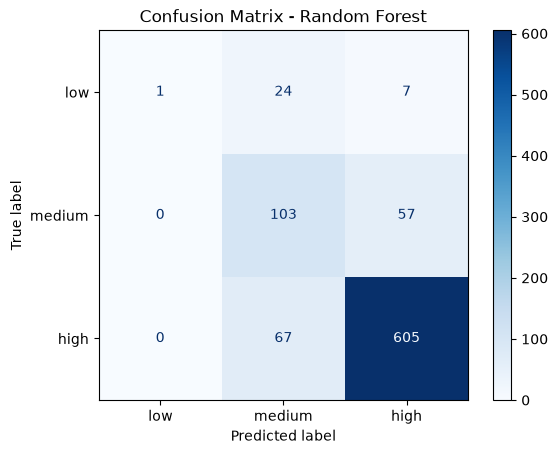

In [147]:
ConfusionMatrixDisplay.from_predictions(y_test_enc, y_pred_rf, display_labels=label_names, cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.show()

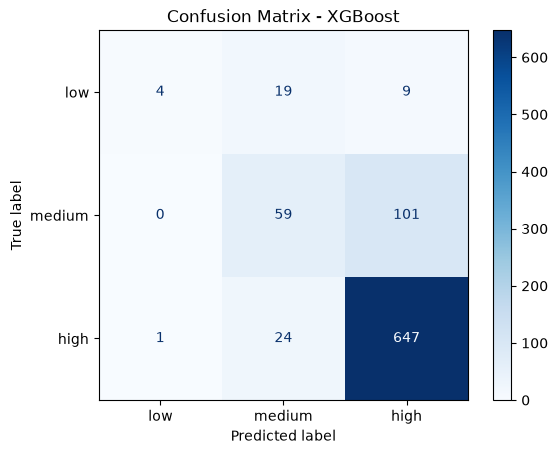

In [148]:
ConfusionMatrixDisplay.from_predictions(y_test_enc, y_pred_xgb, display_labels=label_names, cmap='Blues')
plt.title('Confusion Matrix - XGBoost')
plt.show()

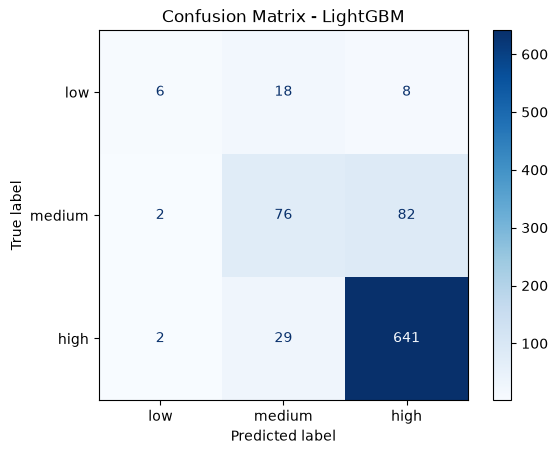

In [149]:
ConfusionMatrixDisplay.from_predictions(y_test_enc, y_pred_lgb, display_labels=label_names, cmap='Blues')
plt.title('Confusion Matrix - LightGBM')
plt.show()

### Model Comparasion

Merangkum metrik utama ketiga model dalam satu tabel untuk menentukan model terbaik, dengan prioritas pada recall dan F1-score kelas `low` serta macro F1

In [152]:
preds = {'Random Forest': y_pred_rf, 'XGBoost': y_pred_xgb, 'LightGBM': y_pred_lgb}

rows = {}
for name, y_pred in preds.items():
    p, r, f, _ = precision_recall_fscore_support(y_test_enc, y_pred, labels=[0, 1, 2], zero_division=0)
    rows[name] = {
        'Low Precision': p[0], 'Low Recall': r[0], 'Low F1': f[0],
        'Macro F1': f1_score(y_test_enc, y_pred, average='macro'),
        'Accuracy': accuracy_score(y_test_enc, y_pred),
    }

pd.DataFrame(rows).T.round(3)

,Low Precision,Low Recall,Low F1,Macro F1,Accuracy
Random Forest,1.0,0.031,0.061,0.515,0.821
XGBoost,0.8,0.125,0.216,0.524,0.822
LightGBM,0.6,0.188,0.286,0.579,0.837


# 10. Model Selection

LightGBM dipilih sebagai model utama untuk tahap tuning, karena menghasilkan Low F1 (0.286), Low Recall (0.188), dan Macro F1 (0.579) tertinggi di antara ketiga model baseline pada data uji, dengan accuracy tertinggi pula (0.837). Keunggulan ini perlu ditafsirkan hati-hati karena kelas low pada data uji hanya 32 sampel, sehingga selisih antar model hanya berkisar beberapa kejadian. Tuning pada tahap berikutnya difokuskan pada LightGBM saja

# 11. Hyperparameter Tuning

Mencari kombinasi hyperparameter LightGBM yang menghasilkan performa terbaik menggunakan validasi silang berbasis waktu, dengan Macro F1 sebagai metrik optimasi. Model hasil tuning dievaluasi satu kali pada data uji dan dibandingkan dengan baseline